# Trabajo Práctico: Entrega Final
## Detección de Duración Anómala de Vuelos Comerciales

**Universidad del Gran Rosario — Licenciatura en Ciencia de Datos**
**Grupo 32:** Luis Gomez Morales · Mariano Tejerina · Emiliano Quiroga · Leandro Bonifacio

---
## 1. Introducción

### Dominio de aplicación
Aviación comercial doméstica en Argentina. La eficiencia operativa del sector impacta en la satisfacción de los pasajeros y en el rendimiento económico de aerolíneas y administradores de aeropuertos. Factores climáticos y fricciones operativas (patrones de espera, desvíos, rodaje lento) hacen que el tiempo real de un vuelo supere con frecuencia lo esperable.

### Alcance
Vuelos **domésticos** (cabotaje) con **Aeroparque Jorge Newbery (AER)** como origen o destino. En el dataset de ANAC utilizado (2019–2026), AER participa en la mayoría de los movimientos domésticos comerciales y acotar el alcance a este aeropuerto permite cruzar los datos con **una única estación meteorológica** de referencia.

### Objetivo del modelo
Predecir, como problema de **clasificación binaria**, si un vuelo tendrá una **duración anómala**, es decir, si su duración real supera el **percentil 90 histórico de su ruta**.

> **Particularidad metodológica.** El dataset de ANAC no incluye el horario programado, por lo que no se puede medir "demora respecto de lo planificado". En su lugar se mide la *anomalía respecto del comportamiento histórico de cada ruta*, que es un problema estadístico distinto, definido a partir de una limitación real de la fuente.

### Beneficios esperados
- Identificar cuellos de botella de forma preventiva.
- Ayudar a operaciones a optimizar **conexiones de pasajeros**.
- Mejorar la gestión de **tripulaciones y recursos en tierra**.

### Fuentes de datos
| Fuente | Contenido | Uso |
|---|---|---|
| **ANAC** | Aterrizajes y despegues (fecha/hora UTC, aeropuerto, origen/destino, aerolínea, modelo de aeronave, pasajeros, clase de vuelo) | Construcción de vuelos, duración y target |
| **SMN** | Datos meteorológicos **diarios** por estación (temperaturas, precipitación, viento, presión, humedad, nubosidad) | Variables climáticas en AER |

**Acceso a los datos originales**
- ANAC – Aterrizajes y despegues: https://datos.gob.ar/dataset/aterrizajes-y-despegues-procesados-por-la-administracion-nacional-de-aviacion-civil-anac
- SMN – Datos diarios por estación: https://www.smn.gob.ar/descarga-de-datos

**Período de los datos**
| Conjunto | Desde | Hasta |
|---|---|---|
| ANAC (crudo) | 01/01/2019 | 31/08/2026 |
| SMN – estación Aeroparque Aero | 01/01/2021 | 31/07/2026 |
| **Dataset final (limpio)** | **15/03/2021** | **31/07/2026** |

El período efectivo queda determinado por dos motivos: el SMN disponible comienza en 2021, y AER estuvo cerrado por obras entre el 01/08/2020 y el 15/03/2021.

### Estructura del notebook
| Contenido | Sección |
|---|---|
| Introducción: dominio, beneficios y objetivo | 1 |
| Configuración, parámetros y carga de datos | 2 |
| EDA sobre datos crudos (calidad, composición, identificación de vuelos, clima) | 3 |
| Limpieza y preprocesamiento, con justificación empírica de los parámetros | 4 |
| Integración con clima y construcción del target | 5 |
| Descripción y EDA del dataset limpio (univariado y bivariado con el target) | 6 |
| Selección de variables | 7 |
| Particionamiento de los datos | 8 |
| Síntesis de hallazgos del EDA | 9 |
| Acceso al dataset limpio | 10 |
| Modelo de AA propuesto y justificación | 11 |
| Preparación de los datos para el modelado | 12 |
| Entrenamiento y ajuste de hiperparámetros | 13 |
| Evaluación del modelo | 14 |
| Conclusiones | 15 |


## 2. Configuración, parámetros y carga de datos
Se importan las librerías, se fijan los parámetros del trabajo y se cargan las dos fuentes: los archivos anuales de ANAC (2019–2026) y el archivo del SMN con registros diarios por estación (2021–2026).

In [1]:
import os, re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

import unicodedata

def arreglar(s):
    # Corrige "mojibake" (UTF-8 leído como cp1252/latin-1): 'DomÃ©stico' -> 'Doméstico'
    if isinstance(s, str) and ("Ã" in s or "Â" in s):
        try:
            return bytes(ord(ch) if ord(ch) < 256 else ch.encode("cp1252")[0] for ch in s).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return s
    return s

def norm(s):
    # minúsculas, sin acentos, sin espacios sobrantes: para comparar nombres de columnas
    s = unicodedata.normalize("NFKD", arreglar(str(s)))
    return s.encode("ascii", "ignore").decode().lower().strip()

# ----------------------------- PARÁMETROS -----------------------------
# Descarga los datos del repositorio (Colab solo abre el notebook, no los archivos de datos)
!test -d /content/repo || git clone https://github.com/erquiroga/ar_2026.git /content/repo

# Carpeta con los archivos: se usa la primera que exista y tenga datos (repo clonado o sesión de Colab)
CANDIDATOS = ["/content/repo/data", "/content"]
DATA_DIR = next((d for d in CANDIDATOS if glob.glob(os.path.join(d, "ad20*"))), "/content")
print("DATA_DIR =", DATA_DIR)
ANAC_GLOBS = [os.path.join(DATA_DIR, "ad20*")]
SMN_GLOB  = os.path.join(DATA_DIR, "smn*")               # archivo(s) del SMN (cualquier extensión)
OUT_PATH  = os.path.join(DATA_DIR, "dataset_limpio.csv") # salida: dataset limpio

# clave interna -> nombre de la columna en el CSV de ANAC
COLS_ANAC = {
    "fecha":      "Fecha UTC",
    "hora":       "Hora UTC",
    "clase":      "Clase de Vuelo (todos los vuelos)",
    "clasif":     "Clasificación Vuelo",
    "tipo":       "Tipo de Movimiento",
    "aeropuerto": "Aeropuerto",
    "orig_dest":  "Origen / Destino",
    "aerolinea":  "Aerolinea Nombre",
    "aeronave":   "Aeronave",     # En ANAC es el MODELO del avión, no la matrícula
    "pasajeros":  "Pasajeros",
}

AP_REF         = "AER"          # código del aeropuerto de referencia en ANAC
ESTACION_SMN   = "AEROPARQUE"   # texto que identifica la estación en el SMN
SMN_NA         = ["", "NA", "-99.9", "-999", "-9999", "S/D"]
UTC_A_LOCAL    = pd.Timedelta(hours=-3)   # Argentina = UTC-3

MIN_DUR, MAX_DUR  = 20, 300     # minutos: rango de duración plausible para cabotaje
FACTOR_MIN, FACTOR_MAX = 0.5, 2.0  # duración válida = [0.5, 2.0] x mediana de su ruta (descarta emparejamientos erróneos)
USAR_PAX_EN_CLAVE = None        # None = decidir automáticamente (ver Sección 4); True/False para forzar
MIN_VUELOS_RUTA   = 30          # mínimo de vuelos de entrenamiento para fijar el umbral de una ruta
PCT_ANOMALO       = 0.90        # percentil que define la anomalía
FRAC_TRAIN        = 0.80        # fracción temporal usada para calcular umbrales y entrenar
SEED              = 42

Cloning into '/content/repo'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (16/16), done.
remote: Total 34 (delta 8), reused 4 (delta 1), pack-reused 17 (from 2)
Receiving objects: 100% (34/34), 46.98 MiB | 7.09 MiB/s, done.
Resolving deltas: 100% (14/14), done.
Updating files: 100% (12/12), done.
DATA_DIR = /content/repo/data


### Parámetros del trabajo:

| Parámetro | Valor | Qué controla | Cómo se eligió |
|---|---|---|---|
| `MIN_DUR` | 20 min | Duración **mínima** aceptada entre un despegue y su aterrizaje. Funciona como **ventana de búsqueda** del emparejamiento (Sección 4): un aterrizaje que ocurre antes de 20 min no puede ser el del despegue analizado. | Cota física: la ruta más corta del alcance (AER–EZE) tiene una mediana de 25 min (se verifica en la **Sección 4.3**). Un valor menor permitiría unir despegues con aterrizajes de otros vuelos. |
| `MAX_DUR` | 300 min | Duración **máxima** aceptada; cierra la ventana de búsqueda. | La ruta más larga (AER–Ushuaia) tiene una mediana de 197 min; 300 min (5 h) deja un margen de ~1,5 veces para vuelos anómalos reales sin aceptar uniones con el vuelo del día siguiente (Sección 4.3). |
| `FACTOR_MIN` | 0,5 | Límite inferior de la duración **relativa a su ruta**: se descarta un vuelo que dure menos de la mitad de la mediana de su ruta. | Un avión no puede volar una ruta en la mitad de su tiempo habitual: esos casos son errores de emparejamiento. En la Sección 4.3 se muestra que el cociente duración/mediana está casi todo concentrado entre 0,8 y 1,5, y que por debajo de 0,5 quedan muy pocos vuelos. |
| `FACTOR_MAX` | 2,0 | Límite superior relativo: se descarta lo que dure más del doble de la mediana de la ruta. | Debe ser **mucho mayor** que el umbral del target (P90 ≈ 1,13 × mediana, Sección 4.4) para no borrar las anomalías que se quieren predecir; por encima de 2 la duración ya no es plausible (implicaría, por ejemplo, 3 h en una ruta de 90 min) y corresponde a un mal emparejamiento. |
| `MIN_VUELOS_RUTA` | 30 | Mínimo de vuelos de entrenamiento para calcular el P90 de una ruta. | Un percentil 90 con menos de 30 observaciones depende de 3 vuelos; es la regla práctica habitual de tamaño mínimo de muestra. |
| `PCT_ANOMALO` | 0,90 | Percentil que define "duración anómala". | Definición del problema: el 10 % más largo de cada ruta. Genera una clase positiva minoritaria pero con suficientes casos para entrenar. |
| `FRAC_TRAIN` | 0,80 | Fracción **cronológica** usada para calcular umbrales y entrenar. | Partición 80/20 habitual, temporal para respetar el orden de los datos (Sección 8). |
| `USAR_PAX_EN_CLAVE` | `None` | Si la cantidad de pasajeros se usa para emparejar. | Se decide con los datos: solo si ≥ 80 % de los pares comparten la cantidad de pasajeros (Sección 4.2). |
| `UTC_A_LOCAL` | −3 h | Conversión de la hora UTC de ANAC a hora argentina. | Argentina no aplica horario de verano desde 2009. |

### 2.1 Carga de ANAC

In [2]:
def leer_csv_anac(path):
    # Prueba dos codificaciones y detecta el separador mirando el encabezado
    for enc in ("utf-8-sig", "latin-1"):
        try:
            with open(path, encoding=enc) as f:
                cab = f.readline()
            sep = max([";", ",", "\t"], key=cab.count)
            df = pd.read_csv(path, sep=sep, encoding=enc, dtype=str)
            df.columns = [arreglar(c).strip() for c in df.columns]
            df["archivo"] = os.path.basename(path)
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo leer {path}")

files = sorted(f for g in ANAC_GLOBS for f in glob.glob(g))
assert files, f"No se encontraron archivos de ANAC en {DATA_DIR}"

partes = [leer_csv_anac(f) for f in files]

resumen = pd.DataFrame({
    "archivo": [p["archivo"].iloc[0] for p in partes],
    "filas": [len(p) for p in partes],
    "columnas": [p.shape[1] - 1 for p in partes],
})
display(resumen)

raw = pd.concat(partes, ignore_index=True)

mapa = {norm(c): c for c in raw.columns}
faltan = [v for v in COLS_ANAC.values() if norm(v) not in mapa]
assert not faltan, f"Columnas no encontradas: {faltan}. Disponibles: {list(raw.columns)}"

print("\nDimensiones del dataset crudo de ANAC:", raw.shape)
display(raw.head())
print("\nColumnas comunes a todos los archivos:", list(partes[0].columns[:-1]))

,archivo,filas,columnas
0,ad2019,580764,12
1,ad2020,212726,12
2,ad2021,329781,12
3,ad2022,106949,12
4,ad2023,557152,12
5,ad2024,578602,12
6,ad2025,597784,12
7,ad2026,371802,13



Dimensiones del dataset crudo de ANAC: (3335560, 14)


,Fecha UTC,Hora UTC,Clase de Vuelo (todos los vuelos),Clasificación Vuelo,Tipo de Movimiento,Aeropuerto,Origen / Destino,Aerolinea Nombre,Aeronave,Pasajeros,PAX,Calidad dato,archivo,Matrícula
0,01/01/2019,0:01,Regular,Domestico,ATERRIZAJE,EZE,SAL,AEROLINEAS ARGENTINAS SA,0,"44,00","22,00",DEFINITIVO,ad2019,NaN
1,01/01/2019,0:01,Regular,Internacional,ATERRIZAJE,EZE,SBGL,TRANSPORTES AEREOS DEL MERCOSUR,0,"165,00","165,00",DEFINITIVO,ad2019,NaN
2,01/01/2019,0:03,Regular,Domestico,ATERRIZAJE,AER,SIS,AUSTRAL LINEAS AEREAS-CIELOS DEL SUR S.A,0,"11,00","5,50",DEFINITIVO,ad2019,NaN
3,01/01/2019,0:04,Regular,Internacional,ATERRIZAJE,EZE,SBGR,TRANSPORTES AEREOS DEL MERCOSUR,0,"69,00","69,00",DEFINITIVO,ad2019,NaN
4,01/01/2019,0:06,Regular,Internacional,ATERRIZAJE,AER,SBGR,LAN ARGENTINA S.A. (LATAM AIRLINES),0,"53,00","53,00",DEFINITIVO,ad2019,NaN



Columnas comunes a todos los archivos: ['Fecha UTC', 'Hora UTC', 'Clase de Vuelo (todos los vuelos)', 'Clasificación Vuelo', 'Tipo de Movimiento', 'Aeropuerto', 'Origen / Destino', 'Aerolinea Nombre', 'Aeronave', 'Pasajeros', 'PAX', 'Calidad dato']


**Interpretación.**
- Se leyeron **8 archivos anuales** (2019–2026) con un total de **3.335.560 registros**. Cada registro es un **movimiento** (un despegue o un aterrizaje), no un vuelo.
- Los 8 archivos comparten 12 columnas; el de 2026 trae una columna adicional, `Matrícula`.
- La vista previa ya muestra tres particularidades que condicionan la limpieza: los pasajeros usan coma decimal (`44,00`), el mismo valor aparece escrito de distintas formas (`ATERRIZAJE` en mayúsculas) y `Aeronave` viene en `0` en los registros de 2019.

### 2.2 Carga del SMN

In [3]:
def leer_smn(path):
    # Archivo separado por tabulaciones; la primera línea viene vacía y pandas la saltea sola
    w = pd.read_csv(path, sep="\t", dtype=str, encoding="latin-1")
    w.columns = [c.strip().upper() for c in w.columns]
    for c in w.columns:
        w[c] = w[c].str.strip()
    return w

smn_files = sorted(glob.glob(SMN_GLOB))
assert smn_files, f"No se encontraron archivos del SMN en {DATA_DIR}"

partes_smn = [leer_smn(f) for f in smn_files]
resumen_smn = pd.DataFrame({
    "archivo": [os.path.basename(f) for f in smn_files],
    "filas": [len(p) for p in partes_smn],
    "columnas": [p.shape[1] for p in partes_smn],
})
display(resumen_smn)

smn_all = pd.concat(partes_smn, ignore_index=True)
print("\nDimensiones del dataset crudo del SMN:", smn_all.shape)
display(smn_all.head())
print("\nColumnas:", list(smn_all.columns))

,archivo,filas,columnas
0,smn_datos_meteorologicos_desde_2021.lst,182489,14



Dimensiones del dataset crudo del SMN: (182489, 14)


,NRO_OMM,NOMBRE,FECHA,TMAX,TMIN,TMEDIA,PRECIP,HELIOF,VTO_MDIR,VTO_MVEL,VEL_MED,PRE_EST,HUM_REL,NUB_TOT
0,87007,LA QUIACA OBSERVATORIO,01/01/2021,24,8.2,15.5,,11.9,9,15,5,671.9,60,2
1,87007,LA QUIACA OBSERVATORIO,02/01/2021,22,9.2,14.5,2,7.6,23,33,6,671.6,64,4
2,87007,LA QUIACA OBSERVATORIO,03/01/2021,24.8,7.5,14.5,6,10.9,5,24,8,668.9,64,3
3,87007,LA QUIACA OBSERVATORIO,04/01/2021,17,5.2,10.7,5,6.6,5,15,5,667.7,74,5
4,87007,LA QUIACA OBSERVATORIO,05/01/2021,16.7,5,9.5,2,6.7,23,15,6,669.4,74,7



Columnas: ['NRO_OMM', 'NOMBRE', 'FECHA', 'TMAX', 'TMIN', 'TMEDIA', 'PRECIP', 'HELIOF', 'VTO_MDIR', 'VTO_MVEL', 'VEL_MED', 'PRE_EST', 'HUM_REL', 'NUB_TOT']


**Interpretación.**
- El archivo del SMN tiene **182.489 registros diarios** de **todas las estaciones del país** (la vista previa empieza por La Quiaca), con 14 columnas. Para este trabajo solo interesa la estación de Aeroparque.
- Algunos campos aparecen vacíos (por ejemplo `PRECIP` en la primera fila).

## 3. Análisis Exploratorio de Datos
Se examina la estructura, la calidad y las distribuciones principales:

- 3.1 Calidad: tipos, nulos y categorías.
- 3.2 Composición y cobertura temporal.
- 3.3 Distribuciones principales.
- 3.4 ¿Cómo identificar un vuelo? (aeronave, matrícula y pasajeros).
- 3.5 Clima (SMN).
- 3.6 Síntesis: de los hallazgos a las decisiones de limpieza.

### 3.1 Calidad: tipos, nulos y categorías

In [4]:
# Preparación mínima para poder explorar: se seleccionan las columnas, se corrige la codificación
# y se convierten tipos (fecha+hora y pasajeros). La limpieza propiamente dicha se hace en la Sección 4.
inv = {mapa[norm(v)]: k for k, v in COLS_ANAC.items()}
anac = raw.rename(columns=inv)[list(COLS_ANAC)].copy()

def limpiar_texto(s):
    cache = {u: (arreglar(u).strip() if isinstance(u, str) else u) for u in s.dropna().unique()}
    return s.map(cache).replace({"": np.nan})

for c in ["clase", "clasif", "tipo", "aeropuerto", "orig_dest", "aerolinea", "aeronave"]:
    anac[c] = limpiar_texto(anac[c].astype("object"))

anac["pasajeros"] = pd.to_numeric(anac["pasajeros"].astype("object").str.replace(",", ".", regex=False), errors="coerce")
anac["dt"] = pd.to_datetime(anac["fecha"].astype(str) + " " + anac["hora"].astype(str),
                            dayfirst=True, errors="coerce")

print(f"Rango temporal: {anac['dt'].min()}  ->  {anac['dt'].max()}")
print(f"Fechas/horas no interpretables: {anac['dt'].isna().sum()}\n")

nulos = anac.isna().mean().mul(100).round(2).sort_values(ascending=False).rename("% nulos")
display(nulos.to_frame())

for c in ["clasif", "tipo", "clase"]:
    print(f"\n--- {c} ---")
    print(anac[c].value_counts(dropna=False).head(12))

Rango temporal: 2019-01-01 00:01:00  ->  2026-08-31 23:57:00
Fechas/horas no interpretables: 0



,% nulos
aerolinea,5.47
hora,0.00
fecha,0.00
clase,0.00
clasif,0.00
aeropuerto,0.00
tipo,0.00
orig_dest,0.00
aeronave,0.00
pasajeros,0.00



--- clasif ---
clasif
Doméstico        2236039
Internacional     623615
Domestico         475906
Name: count, dtype: int64

--- tipo ---
tipo
Despegue      1386797
Aterrizaje    1367998
DESPEGUE       291590
ATERRIZAJE     289174
NaN                 1
Name: count, dtype: int64

--- clase ---
clase
Regular                                   1888840
Vuelo Privado con Matrícula Nacional       476260
Vuelo Escuela                              454512
No Regular                                 264681
Vuelo Oficial Nacional                     184171
Vuelo Privado con Matrícula Extranjera      27286
Vuelo de Adiestramiento                     24976
Trabajo Aéreo                               11844
Vuelo Oficial Extranjero                     2990
Name: count, dtype: int64


**Interpretación.**
- **Fechas:** el período va del 01/01/2019 al 31/08/2026 y **ninguna** fecha u hora quedó sin interpretar.
- **Nulos explícitos:** son mínimos. Solo `aerolinea` tiene un 5,47 % de nulos, y `tipo` tiene un único registro vacío.
- **Categorías duplicadas por escritura:** `clasif` tiene "Doméstico" (2.236.039) y "Domestico" (475.906); `tipo` tiene "Despegue"/"Aterrizaje" y sus versiones en mayúsculas (291.590 + 289.174 = 580.764 registros, exactamente la cantidad de filas del archivo 2019). Requieren normalización para que el mismo valor no se cuente como dos categorías distintas.
- **Clase de vuelo:** hay 9 clases; además de "Regular" y "No Regular" aparecen vuelos privados, de escuela, oficiales, de adiestramiento y trabajo aéreo, que no forman parte del alcance comercial.

### 3.2 Composición y cobertura temporal

In [5]:
# Composición del crudo: ámbito, clase de vuelo, peso de AER y cobertura por año
ambito = np.where(anac["clasif"].astype(str).map(norm).str.contains("dom"), "Doméstico", "Internacional")
print("Ámbito del movimiento (%):")
print(pd.Series(ambito).value_counts(normalize=True).mul(100).round(1).to_string())

print("\nClase de vuelo (%):")
print(anac["clase"].value_counts(normalize=True).mul(100).round(1).to_string())
comercial = anac["clase"].str.contains("regular", case=False, na=False)
print(f"\nComerciales (Regular + No Regular): {comercial.mean():.1%}")

dom_com = (ambito == "Doméstico") & comercial
toca_aer = (anac["aeropuerto"].str.upper() == AP_REF) | (anac["orig_dest"].str.upper() == AP_REF)
print(f"Movimientos domésticos comerciales: {dom_com.sum():,} | de ellos involucran a {AP_REF}: {toca_aer[dom_com].mean():.1%}")

print("\nCobertura por año:")
cob = anac.groupby(anac["dt"].dt.year)["dt"].agg(
    registros="size", desde=lambda s: s.min().date(), hasta=lambda s: s.max().date(), meses_con_datos=lambda s: s.dt.month.nunique())
display(cob)

Ámbito del movimiento (%):
Doméstico        81.3
Internacional    18.7

Clase de vuelo (%):
clase
Regular                                   56.6
Vuelo Privado con Matrícula Nacional      14.3
Vuelo Escuela                             13.6
No Regular                                 7.9
Vuelo Oficial Nacional                     5.5
Vuelo Privado con Matrícula Extranjera     0.8
Vuelo de Adiestramiento                    0.7
Trabajo Aéreo                              0.4
Vuelo Oficial Extranjero                   0.1

Comerciales (Regular + No Regular): 64.6%
Movimientos domésticos comerciales: 1,615,013 | de ellos involucran a AER: 63.9%

Cobertura por año:


,registros,desde,hasta,meses_con_datos
dt,,,,
2019,580764,2019-01-01,2019-12-31,12
2020,212726,2020-01-01,2020-12-31,12
2021,329781,2021-01-01,2021-12-31,12
2022,106949,2022-01-01,2022-04-04,4
2023,557152,2023-01-01,2023-12-31,12
2024,578602,2024-01-01,2024-12-31,12
2025,597784,2025-01-01,2025-12-31,12
2026,371802,2026-01-01,2026-08-31,8


**Interpretación.**
- **Ámbito:** el 81,3 % de los movimientos es doméstico y el 18,7 % internacional.
- **Clase:** solo el **64,6 %** es comercial (Regular 56,6 % + No Regular 7,9 %). El 35,4 % restante son vuelos privados (14,3 % + 0,8 %), de escuela (13,6 %), oficiales y otros, con patrones operativos distintos.
- **Peso de AER:** de los 1.615.013 movimientos domésticos comerciales, **el 63,9 % involucra a Aeroparque**, lo que confirma que acotar el alcance a AER conserva la mayor parte de la operación comercial doméstica.
- **Cobertura:** todos los años tienen 12 meses de datos **excepto 2022**, cuyo archivo termina el **04/04/2022** (4 meses), y 2026, que llega hasta el 31/08. El hueco de mayo a diciembre de 2022 es una **falta de datos de la fuente**, no una caída de la actividad.

### 3.3 Distribuciones principales

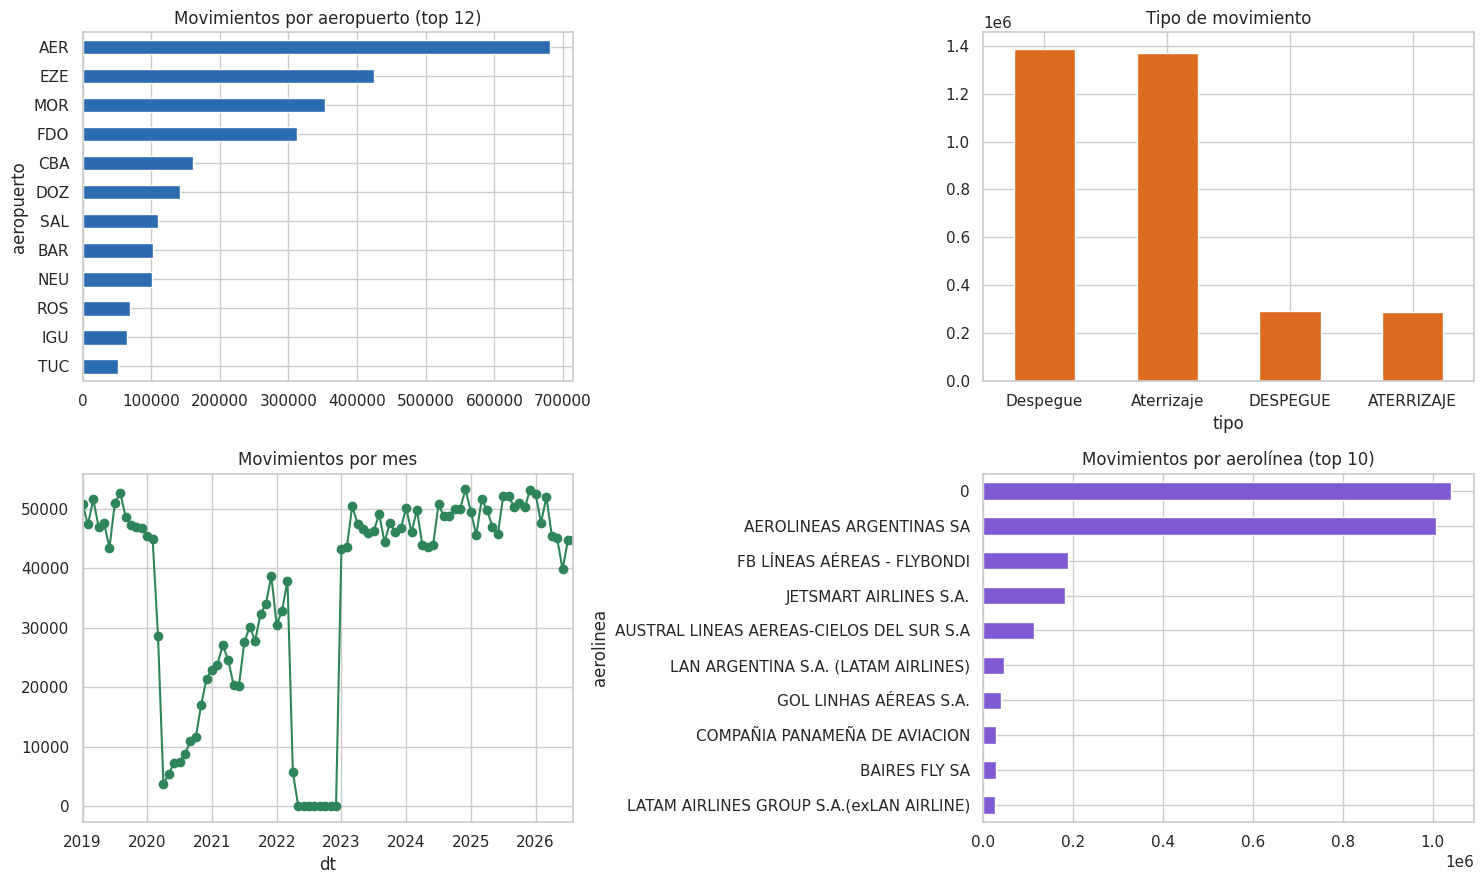

Top 5 aeropuertos (% de movimientos): {'AER': 20.4, 'EZE': 12.7, 'MOR': 10.6, 'FDO': 9.4, 'CBA': 4.8}
Top 5 aerolíneas (% de movimientos con dato): {'0': 33.0, 'AEROLINEAS ARGENTINAS SA': 32.0, 'FB LÍNEAS AÉREAS - FLYBONDI': 6.0, 'JETSMART AIRLINES S.A.': 5.8, 'AUSTRAL LINEAS AEREAS-CIELOS DEL SUR S.A': 3.6}
Meses sin ningún movimiento: ['2022-05', '2022-06', '2022-07', '2022-08', '2022-09', '2022-10', '2022-11', '2022-12']
Promedio mensual 2019: 48,397 | abril 2020: 3,775 (8% de 2019) | promedio 2025: 49,815 (103% de 2019)


In [6]:
# Distribuciones principales del crudo de ANAC: aeropuertos, tipo de movimiento, evolución mensual y aerolíneas
fig, ax = plt.subplots(2, 2, figsize=(15, 9))

anac["aeropuerto"].value_counts().head(12).sort_values().plot.barh(ax=ax[0, 0], color="#2b6cb0")
ax[0, 0].set_title("Movimientos por aeropuerto (top 12)")

anac["tipo"].value_counts().plot.bar(ax=ax[0, 1], color="#dd6b20", rot=0)
ax[0, 1].set_title("Tipo de movimiento")

(anac.dropna(subset=["dt"]).set_index("dt").resample("MS").size()
     .plot(ax=ax[1, 0], marker="o", color="#2f855a"))
ax[1, 0].set_title("Movimientos por mes")

anac["aerolinea"].value_counts().head(10).sort_values().plot.barh(ax=ax[1, 1], color="#805ad5")
ax[1, 1].set_title("Movimientos por aerolínea (top 10)")

plt.tight_layout(); plt.show()

# Valores que se comentan en la interpretación
print("Top 5 aeropuertos (% de movimientos):", anac["aeropuerto"].value_counts(normalize=True).head(5).mul(100).round(1).to_dict())
print("Top 5 aerolíneas (% de movimientos con dato):", anac["aerolinea"].value_counts(normalize=True).head(5).mul(100).round(1).to_dict())
mens = anac.set_index("dt").resample("MS").size()
print("Meses sin ningún movimiento:", [m.strftime("%Y-%m") for m in mens[mens == 0].index])
m19 = mens["2019"].mean()
print(f"Promedio mensual 2019: {m19:,.0f} | abril 2020: {mens['2020-04'].iloc[0]:,} ({mens['2020-04'].iloc[0]/m19:.0%} de 2019)"
      f" | promedio 2025: {mens['2025'].mean():,.0f} ({mens['2025'].mean()/m19:.0%} de 2019)")

**Interpretación.**
- **Aeropuertos:** AER es el de mayor movimiento (20,4 % del total), seguido por EZE (12,7 %). Morón (MOR, 10,6 %) y San Fernando (FDO, 9,4 %) aparecen 3.º y 4.º: son aeródromos de aviación general y escuela, coherente con el 35,4 % de vuelos no comerciales de 3.2.
- **Tipo de movimiento:** el gráfico muestra **cuatro** barras en lugar de dos por la diferencia de mayúsculas detectada en 3.1. Despegues y aterrizajes están balanceados, como se espera si cada vuelo genera un registro de cada tipo.
- **Evolución mensual:** el promedio de 2019 es de 48.397 movimientos por mes; en abril de 2020 cae a 3.775 (8 % de ese nivel) por la pandemia y se recupera gradualmente durante 2021. Entre mayo y diciembre de 2022 la serie vale **cero**, que corresponde al hueco de cobertura del archivo 2022 (3.2). En 2025 el promedio mensual (49.815) ya supera al de 2019 (103 %).
- **Aerolíneas:** el valor más frecuente es `"0"` (33,0 % de los registros con dato), por encima de Aerolíneas Argentinas (32,0 %), Flybondi (6,0 %), JetSMART (5,8 %) y Austral (3,6 %). Es un "sin dato" encubierto.

### 3.4 Identificación de vuelos

In [7]:
# Columna 'Aeronave': ¿identifica un avión individual (matrícula) o un modelo?
print("Valores distintos de 'aeronave':", anac["aeronave"].nunique())
print(anac["aeronave"].value_counts().head(10))
print(f"\nRegistros con aeronave = '0' (sin informar): {(anac['aeronave'] == '0').mean():.1%}")

# ¿Hay una columna de matrícula? % de registros con dato, por archivo
print("\n% de registros con matrícula informada, por archivo:")
print(raw[mapa["matricula"]].notna().groupby(raw["archivo"]).mean().mul(100).round(1))

print("\nPasajeros por movimiento:")
display(anac["pasajeros"].describe().to_frame().T)
print(f"Movimientos con 0 pasajeros: {(anac['pasajeros'] == 0).mean():.1%} | sin dato: {anac['pasajeros'].isna().mean():.1%}")

print("\n% de registros con aeronave = '0' y con 0 pasajeros, por archivo:")
display(pd.DataFrame({"aeronave_0": anac["aeronave"] == "0", "pasajeros_0": anac["pasajeros"] == 0})
          .groupby(raw["archivo"]).mean().mul(100).round(1))

Valores distintos de 'aeronave': 982
aeronave
0                   1244441
EMB-ERJ190100IGW     330557
AIB-A320-232         124262
BO-737-8              83305
BO-737-800            78138
CE-152                63699
CE-150-M              60805
CE-150-L              56036
BO-737-8Q8            55394
BO-B737-800           55141
Name: count, dtype: int64

Registros con aeronave = '0' (sin informar): 37.3%

% de registros con matrícula informada, por archivo:
archivo
ad2019      0.0
ad2020      0.0
ad2021      0.0
ad2022      0.0
ad2023      0.0
ad2024      0.0
ad2025      0.0
ad2026    100.0
Name: Matrícula, dtype: float64

Pasajeros por movimiento:


,count,mean,std,min,25%,50%,75%,max
pasajeros,3335559.0,76.40849,77.451567,0.0,0.0,76.0,148.0,953.0


Movimientos con 0 pasajeros: 34.7% | sin dato: 0.0%

% de registros con aeronave = '0' y con 0 pasajeros, por archivo:


,aeronave_0,pasajeros_0
archivo,,
ad2019,100.0,30.4
ad2020,85.3,48.1
ad2021,14.1,52.0
ad2022,13.7,37.1
ad2023,15.6,30.1
ad2024,17.0,34.4
ad2025,22.7,31.5
ad2026,26.8,29.9


**Interpretación.**
- `aeronave` tiene **982 valores distintos** y los más frecuentes son modelos (`EMB-ERJ190100IGW`, `AIB-A320-232`, `BO-737-8`…): identifica el **modelo**, no el avión individual. Además, un mismo modelo aparece escrito de varias formas (`BO-737-800` y `BO-B737-800`).
- El 37,3 % de los registros tiene `aeronave = "0"`: es el 100 % en 2019 y el 85,3 % en 2020, y entre el 13,7 % y el 26,8 % desde 2021.
- La **matrícula** (que sí identificaría al avión) existe **solo en el archivo 2026** (100 % de sus registros, 0 % en los demás).
- **Pasajeros:** la mediana es 76 por movimiento, pero el **34,7 % registra 0 pasajeros**, con proporciones de entre 29,9 % y 52,0 % según el año. Esos ceros son esperables en vuelos de escuela, privados o de traslado sin pasajeros.
- **Conclusión para la limpieza:** sin número de vuelo, sin horario programado y sin matrícula (salvo en 2026), la única forma de reconstruir un vuelo es **emparejar cada despegue con su aterrizaje** por ruta, aerolínea y modelo, en orden cronológico.

### 3.5 Clima (SMN, estación Aeroparque)

Registros de la estación 'AEROPARQUE': 2038 | estaciones: ['AEROPARQUE AERO']

Período SMN: 2021-01-01 00:00:00 -> 2026-07-31 00:00:00


,count,mean,std,min,25%,50%,75%,max
tmax,2038.0,22.033072,5.973350,5.7,17.1,22.25,26.700,38.5
tmin,2038.0,14.799313,5.485866,1.4,10.3,14.80,19.100,28.3
tmedia,2038.0,18.287586,5.514161,4.4,13.7,18.40,22.900,32.3
precip,657.0,8.455403,15.773823,0.0,0.0,2.00,9.000,112.0
helio,1707.0,7.251611,3.901790,0.0,4.4,8.40,10.000,13.8
vto_dir,2038.0,15.745339,9.788205,1.0,9.0,12.00,21.000,36.0
vto_max,2038.0,36.964671,10.262616,13.0,30.0,35.00,43.000,104.0
vel_med,2038.0,13.695780,5.456814,3.0,10.0,13.00,17.000,40.0
pre_est,2038.0,1015.372964,6.091918,995.8,1011.0,1015.10,1019.275,1034.2
hum_rel,2038.0,70.772816,12.426195,28.0,62.0,71.00,80.000,100.0



% nulos:
 fecha_clima     0.00
tmax            0.00
tmin            0.00
tmedia          0.00
precip         67.76
helio          16.24
vto_dir         0.00
vto_max         0.00
vel_med         0.00
pre_est         0.00
hum_rel         0.00
nub_tot         0.00
dtype: float64

Días esperados: 2038 | días con registro: 2038
Días con precipitación = 0 registrada: 225


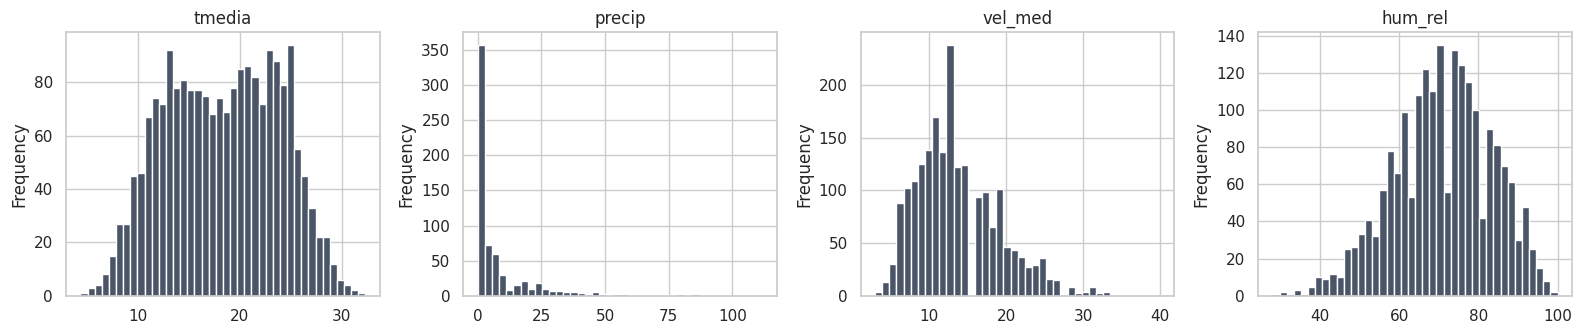

In [8]:
# EDA del clima (SMN): estación de referencia
smn_raw = smn_all[smn_all["NOMBRE"].str.upper().str.contains(ESTACION_SMN, na=False)].copy()
print(f"Registros de la estación '{ESTACION_SMN}':", len(smn_raw), "| estaciones:", list(smn_raw["NOMBRE"].unique()))

COLS_SMN = {"TMAX": "tmax", "TMIN": "tmin", "TMEDIA": "tmedia", "PRECIP": "precip", "HELIOF": "helio",
            "VTO_MDIR": "vto_dir", "VTO_MVEL": "vto_max", "VEL_MED": "vel_med",
            "PRE_EST": "pre_est", "HUM_REL": "hum_rel", "NUB_TOT": "nub_tot"}
smn_raw = smn_raw.rename(columns=COLS_SMN)
VARS_CLIMA = list(COLS_SMN.values())
for c in VARS_CLIMA:
    smn_raw[c] = pd.to_numeric(smn_raw[c].replace(SMN_NA, np.nan), errors="coerce")
smn_raw["fecha_clima"] = pd.to_datetime(smn_raw["FECHA"], dayfirst=True, errors="coerce")

print("\nPeríodo SMN:", smn_raw["fecha_clima"].min(), "->", smn_raw["fecha_clima"].max())
display(smn_raw[VARS_CLIMA].describe().T)
print("\n% nulos:\n", smn_raw[["fecha_clima"] + VARS_CLIMA].isna().mean().mul(100).round(2))

dias = pd.date_range(smn_raw["fecha_clima"].min(), smn_raw["fecha_clima"].max(), freq="D")
print(f"\nDías esperados: {len(dias)} | días con registro: {smn_raw['fecha_clima'].nunique()}")
print("Días con precipitación = 0 registrada:", int((smn_raw["precip"] == 0).sum()))

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
for a, c in zip(ax, ["tmedia", "precip", "vel_med", "hum_rel"]):
    smn_raw[c].dropna().plot.hist(bins=40, ax=a, color="#4a5568"); a.set_title(c)
plt.tight_layout(); plt.show()

**Interpretación.**
- La estación **Aeroparque Aero** tiene **2.038 registros**, uno por día entre el 01/01/2021 y el 31/07/2026, **sin días faltantes**. No incluye visibilidad.
- Las variables continuas tienen rangos plausibles: temperatura media de 4,4 a 32,3 °C (media 18,3), humedad de 28 a 100 %, nubosidad de 0 a 8 octavos, presión de 995,8 a 1034,2 hPa. La ráfaga máxima (`vto_max`) tiene una mediana de 35 km/h y un máximo de 104 km/h, un valor extremo pero posible en un día de tormenta.
- **Nulos:** solo dos variables. `helio` (heliofanía) tiene un 16,2 % de nulos. `precip` tiene un **67,8 %**: de los 657 días con dato, 225 registran 0 mm y 432 registran lluvia (21,2 % de los 2.038 días). Como el SMN sí carga "0" en algunos días, el vacío no puede asumirse siempre como "no llovió".
- `vto_dir` toma valores de 1 a 36: es la dirección del viento en **decenas de grados**, una variable **circular** (36 y 1 son direcciones vecinas).
- Al ser un dato **diario**, todos los vuelos de un mismo día compartirán las mismas condiciones meteorológicas.

### 3.6 Síntesis: de los hallazgos a las decisiones de limpieza
Cada fila retoma un resultado calculado en las celdas anteriores y lo vincula con el paso de la Sección 4 que lo resuelve.

| Hallazgo (sección) | Evidencia | Decisión (paso) |
|---|---|---|
| Mismas categorías escritas distinto (3.1) | "Domestico" 475.906 registros; tipos en mayúsculas 580.764 | Normalizar texto y tipos (1) |
| `"0"` como dato faltante (3.3, 3.4) | 33,0 % de `aerolinea` y 37,3 % de `aeronave` | Agrupar como `DESCONOCIDO` (2) |
| Movimientos fuera del alcance comercial (3.2) | 35,4 % no comercial; 18,7 % internacional | Filtrar doméstico + Regular/No Regular (4) |
| AER concentra la operación (3.2) | 63,9 % de los movimientos domésticos comerciales | Acotar a vuelos que tocan AER (5) |
| No hay identificador de vuelo (3.4) | Sin número de vuelo; matrícula solo en 2026 | Emparejar despegue → aterrizaje (6) |
| Clima solo desde 2021 y diario (3.5) | 2.038 días, 01/01/2021–31/07/2026 | Join por fecha local; el período útil empieza en 2021 (9) |
| Nulos de precipitación con significado incierto (3.5) | 67,8 % nulos, pero 225 días con 0 mm | No interpolar `precip` (8) |
| Hueco de cobertura (3.2) | Archivo 2022 termina el 04/04/2022 | Se documenta como limitación; la partición es temporal (Sección 8) |

## 4. Limpieza y preprocesamiento
Cada paso se apoya en un hallazgo del EDA de la Sección 3 y deja registro de las filas eliminadas.

| # | Tarea | Justificación |
|---|---|---|
| 1 | Corregir codificación, normalizar texto (espacios, mayúsculas) y parsear fecha+hora a `datetime` | En 3.1 se vio la misma categoría escrita de dos formas ("Domestico" en 475.906 registros; tipos en mayúsculas en 580.764). Sin normalizar, se contarían como categorías distintas. |
| 2 | Eliminar registros sin fecha/hora, tipo de movimiento, aeropuerto u origen/destino; agrupar aerolíneas y modelos `"0"` como `DESCONOCIDO` | Sin esos campos no se puede reconstruir el vuelo, e imputarlos inventaría rutas. El `"0"` funciona como dato faltante: es el 33,0 % de `aerolinea` (registros con dato) y el 37,3 % de `aeronave` (3.3 y 3.4). |
| 3 | Eliminar duplicados exactos | Un mismo movimiento repetido generaría emparejamientos falsos. |
| 4 | Conservar solo vuelos domésticos de clase Regular / No Regular | El 35,4 % de los movimientos no es comercial y el 18,7 % es internacional (3.2); tienen patrones operativos distintos y quedan fuera del alcance. |
| 5 | Quedarse con los movimientos que involucran a AER | AER concentra el 63,9 % de los movimientos domésticos comerciales (3.2) y permite usar una sola estación meteorológica. Se hace antes de emparejar para conservar ambos registros de cada vuelo. |
| 6 | Emparejar cada despegue con su aterrizaje por ruta, aerolínea y modelo de aeronave, en orden cronológico y dentro de una ventana de duración válida | No hay número de vuelo y la matrícula solo existe en 2026 (3.4). Los pasajeros se usan en la clave solo si coinciden en al menos el 80 % de los pares (se evalúa en 4.2). |
| 7 | Descartar duraciones fuera de `[MIN_DUR, MAX_DUR]` o de `[FACTOR_MIN, FACTOR_MAX]` × la mediana de la ruta | Una duración imposible indica un emparejamiento incorrecto, no un vuelo anómalo. Los valores se justifican en 4.3. |
| 8 | Clima: interpolar huecos de hasta 2 días, excepto la precipitación | Las variables continuas varían lentamente. La precipitación no se interpola porque el vacío no siempre significa "no llovió" (67,8 % de nulos, pero 225 días cargados con 0 mm, 3.5). |
| 9 | Cruzar cada vuelo con el registro diario del SMN por fecha local | El SMN es diario y empieza el 01/01/2021 (3.5): el cruce es por día y el período útil comienza en 2021. ANAC está en UTC y se convierte a hora local. |
| 10 | Target con umbral P90 por ruta, calculado solo con el período de entrenamiento | Si el umbral usara toda la historia, el período de prueba influiría en la definición del target (fuga de información). |

### 4.1 Filtros por registro (pasos 1 a 5)

In [9]:
log = []
def registrar(desc, antes, despues):
    log.append({"paso": desc, "registros_antes": antes, "registros_despues": despues, "eliminados": antes - despues})

df = anac.copy()

# 1-2. Normalización y nulos clave
for c in ["aeropuerto", "orig_dest", "aerolinea", "aeronave"]:
    df[c] = df[c].map(lambda x: x.upper() if isinstance(x, str) else x)
df["aerolinea"] = df["aerolinea"].replace({"0": "DESCONOCIDO"}).fillna("DESCONOCIDO")
df["aeronave"]  = df["aeronave"].replace({"0": "DESCONOCIDO"}).fillna("DESCONOCIDO")
t = df["tipo"].astype(str).str.lower()
df["tipo"] = np.where(t.str.startswith("desp"), "Despegue", np.where(t.str.startswith("aterr"), "Aterrizaje", None))

n = len(df)
df = df.dropna(subset=["dt", "tipo", "aeropuerto", "orig_dest"])
registrar("Nulos / fechas inválidas en campos clave", n, len(df))

# 3. Duplicados
n = len(df)
df = df.drop_duplicates(subset=["dt", "tipo", "aeropuerto", "orig_dest", "aerolinea", "aeronave", "pasajeros"])
registrar("Duplicados exactos", n, len(df))

# 4. Doméstico y clase regular / no regular
n = len(df)
df = df[df["clasif"].astype(str).map(norm).str.contains("dom|cabotaje", na=False)]
registrar("No doméstico (internacional, etc.)", n, len(df))

n = len(df)
df = df[df["clase"].astype(str).str.contains("regular", case=False, na=False)]
registrar("Clase de vuelo no comercial (privado, trabajo aéreo, etc.)", n, len(df))

# 5. Alcance AER (se conservan ambos registros de cada vuelo: el del propio AER y el del otro aeropuerto)
n = len(df)
df = df[(df["aeropuerto"] == AP_REF) | (df["orig_dest"] == AP_REF)]
registrar(f"Movimientos que no involucran a {AP_REF}", n, len(df))

n = len(df)
df = df[df["aeropuerto"] != df["orig_dest"]]
registrar("Mismo aeropuerto como origen y destino", n, len(df))

pd.DataFrame(log)

,paso,registros_antes,registros_despues,eliminados
0,Nulos / fechas inválidas en campos clave,3335560,3335556,4
1,Duplicados exactos,3335556,3327495,8061
2,"No doméstico (internacional, etc.)",3327495,2704010,623485
3,"Clase de vuelo no comercial (privado, trabajo ...",2704010,1614825,1089185
4,Movimientos que no involucran a AER,1614825,1031646,583179
5,Mismo aeropuerto como origen y destino,1031646,1031079,567


**Interpretación.**
- Los nulos en campos clave son despreciables (4 registros) y los duplicados exactos son 8.061 (0,24 %).
- Los filtros de **alcance** son los que más reducen el volumen: se eliminan 623.485 movimientos internacionales y 1.089.185 no comerciales, y luego 583.179 movimientos que no involucran a AER.
- Quedan **1.031.079 movimientos** (el 30,9 % del crudo), que todavía son registros sueltos de despegue o aterrizaje.

### 4.2 Emparejamiento despegue → aterrizaje (paso 6)

In [10]:
# 6. Emparejamiento despegue -> aterrizaje SIN matrícula ni número de vuelo
# Clave: (origen, destino, aerolínea, modelo de aeronave [, pasajeros]).
# Dentro de cada grupo, cada despegue se une al primer aterrizaje libre que ocurra entre MIN_DUR y MAX_DUR minutos después
# (los vuelos de una misma ruta/aerolínea/modelo conservan prácticamente el orden de salida).
d = df[["dt", "tipo", "aeropuerto", "orig_dest", "aerolinea", "aeronave", "pasajeros"]].copy()
d["t"] = (d["dt"] - pd.Timestamp("2000-01-01")).dt.total_seconds() / 60
d["pax_k"] = d["pasajeros"].fillna(-1)

def emparejar(d, usar_pax):
    key = ["origen", "destino", "aerolinea", "aeronave"] + (["pax_k"] if usar_pax else [])
    dep = d[d["tipo"] == "Despegue"].assign(origen=lambda x: x["aeropuerto"], destino=lambda x: x["orig_dest"])
    ate = d[d["tipo"] == "Aterrizaje"].assign(origen=lambda x: x["orig_dest"], destino=lambda x: x["aeropuerto"])
    ate_d = {}
    for k, g in ate.groupby(key):
        g = g.sort_values("t")
        ate_d[k] = (g["t"].to_numpy(), g["pax_k"].to_numpy())
    filas = []
    for k, g in dep.groupby(key):
        if k not in ate_d:
            continue
        a_t, a_p = ate_d[k]
        g = g.sort_values("t")
        j = 0
        for t0, p0 in zip(g["t"].to_numpy(), g["pax_k"].to_numpy()):
            while j < len(a_t) and a_t[j] < t0 + MIN_DUR:
                j += 1                       # aterrizajes huérfanos (sin despegue propio)
            if j < len(a_t) and a_t[j] <= t0 + MAX_DUR:
                filas.append((k[0], k[1], k[2], k[3], t0, a_t[j], p0, a_p[j]))
                j += 1
    out = pd.DataFrame(filas, columns=["origen", "destino", "aerolinea", "aeronave", "t_sal", "t_lleg", "pax_dep", "pax_ate"])
    return out

ref = pd.Timestamp("2000-01-01")
par0 = emparejar(d, usar_pax=False)
comparte = (par0["pax_dep"] == par0["pax_ate"]).mean()
print(f"Pares sin usar pasajeros: {len(par0):,} | % con igual cantidad de pasajeros en despegue y aterrizaje: {comparte:.1%}")

usar_pax = (comparte >= 0.80) if USAR_PAX_EN_CLAVE is None else USAR_PAX_EN_CLAVE
print("Usar pasajeros como parte de la clave de emparejamiento:", usar_pax)
par = emparejar(d, usar_pax) if usar_pax else par0

n_dep = (d["tipo"] == "Despegue").sum()
vuelos = par.assign(
    dt_salida=ref + pd.to_timedelta(par["t_sal"], unit="m"),
    dt_llegada=ref + pd.to_timedelta(par["t_lleg"], unit="m"),
    pasajeros=par["pax_dep"].where(par["pax_dep"] >= 0),
    duracion_min=par["t_lleg"] - par["t_sal"],
).drop(columns=["t_sal", "t_lleg", "pax_dep", "pax_ate"])
registrar("Emparejamiento despegue-aterrizaje (la unidad pasa a ser 'vuelo'; se parte de los despegues)", n_dep, len(vuelos))
print(f"Despegues emparejados: {len(vuelos):,} de {n_dep:,} ({len(vuelos)/n_dep:.1%})")
display(vuelos["duracion_min"].describe().to_frame().T)

Pares sin usar pasajeros: 484,366 | % con igual cantidad de pasajeros en despegue y aterrizaje: 65.2%
Usar pasajeros como parte de la clave de emparejamiento: False
Despegues emparejados: 484,366 de 515,880 (93.9%)


,count,mean,std,min,25%,50%,75%,max
duracion_min,484366.0,96.604912,36.639618,20.0,74.0,93.0,110.0,300.0


**Interpretación.**
- Se parte de **515.880 despegues**. Sin usar pasajeros se emparejan **484.366** (93,9 %); el 6,1 % restante no encuentra un aterrizaje dentro de la ventana `[MIN_DUR, MAX_DUR]` (por ejemplo, porque el otro registro falta en la fuente).
- Solo el **65,2 %** de los pares tiene la misma cantidad de pasajeros en el despegue y en el aterrizaje. Como no llega al 80 % fijado en los parámetros, los pasajeros **no** se usan como parte de la clave: hacerlo dejaría sin pareja a un tercio de los vuelos reales.
- La duración resultante va de 20 a 300 min (los límites de la ventana) con mediana de 93 min.

### 4.3 Justificación empírica de `MIN_DUR`, `MAX_DUR`, `FACTOR_MIN` y `FACTOR_MAX`
Antes de aplicar el paso 7 se miden, sobre los vuelos ya emparejados, (a) las rutas más cortas y más largas, para ubicar `MIN_DUR` y `MAX_DUR`, y (b) el **cociente duración / mediana de la ruta**, para ubicar `FACTOR_MIN` y `FACTOR_MAX`.

Rutas con menor y mayor mediana de duración (con >= 30 vuelos):


,vuelos,mediana_min
ruta,,
AER-EZE,449,25.0
EZE-AER,701,25.0
ROS-AER,4792,34.0
USU-AER,9875,185.0
AER-GRA,2180,186.0
AER-USU,9764,197.0


MIN_DUR = 20 min  | mediana de la ruta más corta: 25 min
MAX_DUR = 300 min | mediana de la ruta más larga: 197 min -> MAX_DUR equivale a 1.52 x esa mediana

Cociente duración / mediana de la ruta:


,count,mean,std,min,0.1%,1%,5%,50%,95%,99%,99.9%,max
cociente,484366.0,1.019,0.198,0.102,0.379,0.824,0.901,1.0,1.157,1.456,3.574,11.92


  vuelos con cociente < 0.5: 0.21%
  vuelos con cociente < 0.8: 0.77%
  vuelos con cociente > 1.5: 0.88%
  vuelos con cociente > 2.0: 0.40%
  vuelos con cociente > 2.5: 0.25%


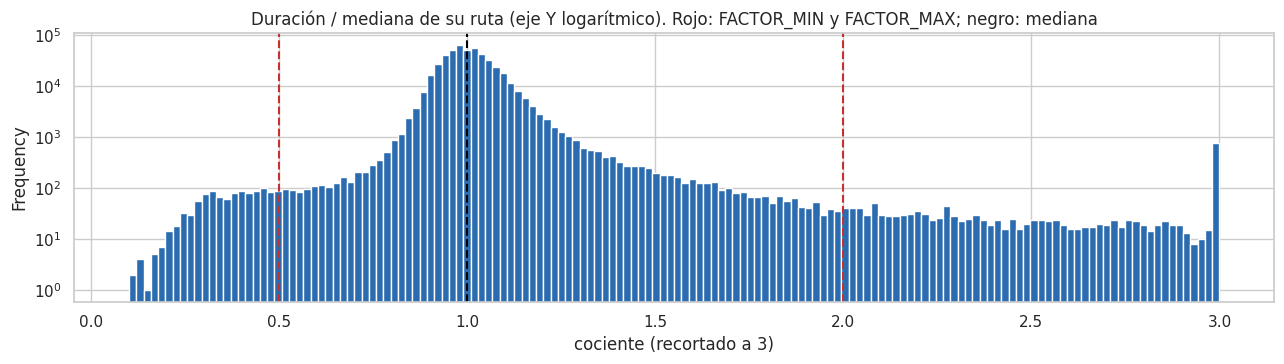

In [11]:
# Rutas extremas y cociente duración / mediana de la ruta, antes de filtrar
tmp = vuelos.assign(ruta=vuelos["origen"] + "-" + vuelos["destino"])
med_ruta = tmp.groupby("ruta")["duracion_min"].agg(vuelos="size", mediana_min="median").sort_values("mediana_min")
med_ruta = med_ruta[med_ruta["vuelos"] >= MIN_VUELOS_RUTA]
print(f"Rutas con menor y mayor mediana de duración (con >= {MIN_VUELOS_RUTA} vuelos):")
display(pd.concat([med_ruta.head(3), med_ruta.tail(3)]))
print(f"MIN_DUR = {MIN_DUR} min  | mediana de la ruta más corta: {med_ruta['mediana_min'].min():.0f} min")
print(f"MAX_DUR = {MAX_DUR} min | mediana de la ruta más larga: {med_ruta['mediana_min'].max():.0f} min "
      f"-> MAX_DUR equivale a {MAX_DUR / med_ruta['mediana_min'].max():.2f} x esa mediana")

ratio = tmp["duracion_min"] / tmp.groupby("ruta")["duracion_min"].transform("median")
print("\nCociente duración / mediana de la ruta:")
display(ratio.describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).to_frame("cociente").T.round(3))
for f in [0.5, 0.8]:
    print(f"  vuelos con cociente < {f}: {(ratio < f).mean():.2%}")
for f in [1.5, 2.0, 2.5]:
    print(f"  vuelos con cociente > {f}: {(ratio > f).mean():.2%}")

fig, ax = plt.subplots(figsize=(13, 3.8))
ratio.clip(0, 3).plot.hist(bins=150, ax=ax, color="#2b6cb0", log=True)
for f, col in [(FACTOR_MIN, "#c53030"), (FACTOR_MAX, "#c53030"), (1.0, "black")]:
    ax.axvline(f, color=col, ls="--")
ax.set_title("Duración / mediana de su ruta (eje Y logarítmico). Rojo: FACTOR_MIN y FACTOR_MAX; negro: mediana")
ax.set_xlabel("cociente (recortado a 3)")
plt.tight_layout(); plt.show()

**Interpretación.**

*Límites absolutos (`MIN_DUR`, `MAX_DUR`):*
- Las rutas más cortas son AER–EZE y EZE–AER (mediana **25 min**), seguidas por ROS–AER (34 min). `MIN_DUR = 20` queda apenas por debajo de la ruta más corta: no descarta vuelos reales y evita unir un despegue con un aterrizaje de otro vuelo ocurrido a los pocos minutos.
- La ruta más larga es AER–USU (Ushuaia, mediana **197 min**), seguida por AER–GRA y USU–AER. `MAX_DUR = 300` equivale a **1,52 veces** esa mediana: deja margen para un vuelo demorado de la ruta más larga.

*Límites relativos (`FACTOR_MIN`, `FACTOR_MAX`):*
- El cociente duración/mediana de la ruta está muy concentrado alrededor de 1: el 98 % de los vuelos está entre **0,82 (P1) y 1,46 (P99)**.
- El histograma (eje logarítmico) muestra un pico central y, a ambos lados, un **"piso" plano** de alrededor de 100 vuelos por intervalo que no decrece al alejarse. Ese patrón es la firma de **emparejamientos erróneos**: una demora real se vuelve cada vez menos frecuente cuanto más larga es, mientras que un despegue unido al aterrizaje equivocado puede caer en cualquier punto de la ventana.
- Con `[0,5; 2,0]` se eliminan los extremos claramente imposibles: 0,21 % por debajo de 0,5 y 0,40 % por encima de 2,0 (0,61 % en total).
- `FACTOR_MAX = 2,0` está muy por encima del umbral del target (el P90 de una ruta es, en promedio, 1,13 veces su mediana, ver 4.4), así que **no elimina las anomalías que se quieren predecir**. Un límite más estricto (por ejemplo 1,5) eliminaría más errores, pero también cortaría la cola de vuelos realmente demorados.
- Es un compromiso: el piso plano continúa dentro del intervalo, por lo que queda alrededor de un 1 % de vuelos con duración dudosa.

### 4.4 Filtro de duraciones (paso 7)

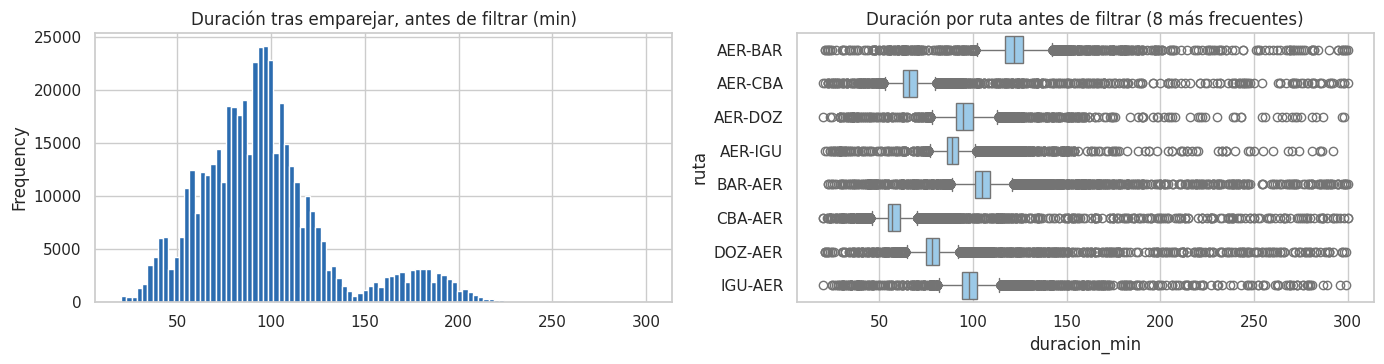

Resumen de la limpieza de vuelos:


,paso,registros_antes,registros_despues,eliminados
0,Nulos / fechas inválidas en campos clave,3335560,3335556,4
1,Duplicados exactos,3335556,3327495,8061
2,"No doméstico (internacional, etc.)",3327495,2704010,623485
3,"Clase de vuelo no comercial (privado, trabajo ...",2704010,1614825,1089185
4,Movimientos que no involucran a AER,1614825,1031646,583179
5,Mismo aeropuerto como origen y destino,1031646,1031079,567
6,Emparejamiento despegue-aterrizaje (la unidad ...,515880,484366,31514
7,"Duración fuera de [20, 300] min",484366,484366,0
8,"Duración fuera de [0.5, 2.0] x mediana de la ruta",484366,481408,2958


Vuelos resultantes: 481408 | rutas distintas: 92

Relación P90 / mediana por ruta:


,count,mean,std,min,25%,50%,75%,max
0,92.0,1.134538,0.100522,1.013333,1.092547,1.106794,1.128738,1.65625



Vuelos por debajo de 0,8 x mediana: 0.56% | por encima de 1,5 x mediana: 0.49%


In [12]:
# 7. Validación de duraciones: rango global y relativo a la mediana de cada ruta
vuelos["ruta"] = vuelos["origen"] + "-" + vuelos["destino"]

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
vuelos["duracion_min"].plot.hist(bins=100, ax=ax[0], color="#2b6cb0")
ax[0].set_title("Duración tras emparejar, antes de filtrar (min)")
top = vuelos["ruta"].value_counts().head(8).index
sns.boxplot(data=vuelos[vuelos["ruta"].isin(top)], y="ruta", x="duracion_min", ax=ax[1], color="#90cdf4")
ax[1].set_title("Duración por ruta antes de filtrar (8 más frecuentes)")
plt.tight_layout(); plt.show()

n = len(vuelos)
vuelos = vuelos[vuelos["duracion_min"].between(MIN_DUR, MAX_DUR)]
registrar(f"Duración fuera de [{MIN_DUR}, {MAX_DUR}] min", n, len(vuelos))

med = vuelos.groupby("ruta")["duracion_min"].transform("median")
n = len(vuelos)
vuelos = vuelos[(vuelos["duracion_min"] >= FACTOR_MIN * med) & (vuelos["duracion_min"] <= FACTOR_MAX * med)].copy()
registrar(f"Duración fuera de [{FACTOR_MIN}, {FACTOR_MAX}] x mediana de la ruta", n, len(vuelos))

vuelos["sentido"] = np.where(vuelos["origen"] == AP_REF, "sale_AER", "llega_AER")
vuelos = vuelos.reset_index(drop=True)

print("Resumen de la limpieza de vuelos:")
display(pd.DataFrame(log))
print("Vuelos resultantes:", len(vuelos), "| rutas distintas:", vuelos["ruta"].nunique())

r = vuelos.groupby("ruta")["duracion_min"].agg(mediana="median", p90=lambda s: s.quantile(0.90))
print("\nRelación P90 / mediana por ruta:")
display((r["p90"] / r["mediana"]).describe().to_frame().T)

rel = vuelos["duracion_min"] / vuelos.groupby("ruta")["duracion_min"].transform("median")
print(f"\nVuelos por debajo de 0,8 x mediana: {(rel < 0.8).mean():.2%} | por encima de 1,5 x mediana: {(rel > 1.5).mean():.2%}")

**Interpretación.**
- El filtro `[20, 300]` min no elimina ningún vuelo porque el emparejamiento ya buscó aterrizajes **solo dentro de esa ventana**: en la práctica `MIN_DUR` y `MAX_DUR` actúan en el paso 6.
- El filtro relativo elimina **2.958 vuelos** (0,61 %) y quedan **481.408 vuelos en 92 rutas**.
- El boxplot por ruta muestra que cada ruta tiene una duración típica propia (CBA–AER ronda 1 h y AER–BAR, 2 h): un umbral fijo de anomalía no serviría para todas.
- El P90 de cada ruta es en promedio **1,13 veces su mediana** (mediana 1,11; rango 1,01–1,66): en términos prácticos, un vuelo "anómalo" dura alrededor de un 10–15 % más de lo habitual en su ruta.
- Tras el filtro, el 0,56 % de los vuelos dura menos de 0,8 veces la mediana y el 0,49 % más de 1,5 veces: es el ~1 % de duraciones dudosas mencionado en 4.3.

## 5. Integración con clima y construcción del target

**Clima.** El SMN es **diario**, por lo que el cruce se hace por **fecha local**, usando el día del momento en que el vuelo toca AER: **despegue** si AER es el origen, **aterrizaje** si AER es el destino. Se completa la serie diaria y se interpolan linealmente huecos de hasta 2 días (salvo la precipitación).

**Target.** `duracion_anomala = 1` si la duración supera el **P90 de la ruta**. Los umbrales se calculan únicamente con el primer 80 % cronológico de los vuelos para evitar fuga de información hacia el período de prueba.

### 5.1 Clima diario e integración con los vuelos (pasos 8 y 9)

In [13]:
# 8. Clima: serie diaria completa + interpolación de huecos cortos
w = smn_raw.dropna(subset=["fecha_clima"]).drop_duplicates("fecha_clima").set_index("fecha_clima").sort_index()[VARS_CLIMA]
w = w.resample("D").asfreq()

nulos_antes = w.isna().sum()
cont = [c for c in VARS_CLIMA if c != "precip"]
w[cont] = w[cont].interpolate(method="linear", limit=2, limit_area="inside")
nulos_despues = w.isna().sum()
display(pd.DataFrame({"nulos_antes": nulos_antes, "nulos_despues": nulos_despues}))

w = w.reset_index()
w["fecha_clima"] = w["fecha_clima"].astype("datetime64[ns]")

# 9. Join por fecha local del momento en que el vuelo toca AER
v = vuelos.copy()
t_ref = v["dt_salida"].where(v["origen"] == AP_REF, v["dt_llegada"])
v["fecha_clima"] = (t_ref + UTC_A_LOCAL).dt.normalize().astype("datetime64[ns]")
v = v.merge(w, on="fecha_clima", how="left")

sin_clima = v[VARS_CLIMA].isna().all(axis=1)
print("Vuelos sin ningún dato climático (fecha fuera del período del SMN):", int(sin_clima.sum()))
n = len(v)
v = v[~sin_clima]
registrar("Sin dato climático del día (fuera del período SMN o hueco largo)", n, len(v))
v = v.sort_values("dt_salida").reset_index(drop=True)
print("Vuelos con clima asociado:", len(v), "| nulos restantes por variable:")
print(v[VARS_CLIMA].isna().sum().to_dict())

,nulos_antes,nulos_despues
tmax,0,0
tmin,0,0
tmedia,0,0
precip,1381,1381
helio,331,320
vto_dir,0,0
vto_max,0,0
vel_med,0,0
pre_est,0,0
hum_rel,0,0


Vuelos sin ningún dato climático (fecha fuera del período del SMN): 120277
Vuelos con clima asociado: 361131 | nulos restantes por variable:
{'tmax': 0, 'tmin': 0, 'tmedia': 0, 'precip': 239575, 'helio': 78063, 'vto_dir': 0, 'vto_max': 0, 'vel_med': 0, 'pre_est': 0, 'hum_rel': 0, 'nub_tot': 0}


**Interpretación.**
- La interpolación de hasta 2 días solo completa **11 días** de heliofanía (331 → 320 nulos): la serie del SMN ya estaba completa en las demás variables continuas. Los 1.381 días sin precipitación se mantienen sin imputar, según lo decidido en 3.5.
- **120.277 vuelos** quedan sin clima porque su fecha está fuera del período del SMN (2019–2020 y agosto de 2026) y se eliminan. Quedan **361.131 vuelos** con clima asociado.
- Persisten nulos solo en `precip` (239.575) y `helio` (78.063).

### 5.2 Construcción del target (paso 10)

In [14]:
# 10. Target con umbral P90 por ruta, calculado solo con el período de entrenamiento
fecha_corte = v["dt_salida"].quantile(FRAC_TRAIN)
v["es_train"] = (v["dt_salida"] <= fecha_corte).astype(int)
print("Fecha de corte train/test:", fecha_corte)

stats = (v[v["es_train"] == 1].groupby("ruta")["duracion_min"]
           .agg(n_train="size", mediana_ruta_min="median", p90_ruta_min=lambda s: s.quantile(PCT_ANOMALO))
           .reset_index())
stats = stats[stats["n_train"] >= MIN_VUELOS_RUTA]
print(f"Rutas con >= {MIN_VUELOS_RUTA} vuelos de entrenamiento: {len(stats)} de {v['ruta'].nunique()}")

n = len(v)
v = v.merge(stats[["ruta", "mediana_ruta_min", "p90_ruta_min"]], on="ruta", how="inner")
registrar(f"Rutas con menos de {MIN_VUELOS_RUTA} vuelos de entrenamiento (umbral no confiable)", n, len(v))

v["duracion_anomala"] = (v["duracion_min"] > v["p90_ruta_min"]).astype(int)

# Variables de calendario (conocidas antes del vuelo), en hora local Argentina
loc = v["dt_salida"] + UTC_A_LOCAL
v["hora_salida_local"] = loc.dt.hour
v["dia_semana"]        = loc.dt.dayofweek
v["mes"]               = loc.dt.month
v["fin_de_semana"]     = (v["dia_semana"] >= 5).astype(int)

cols_final = ["dt_salida", "dt_llegada", "origen", "destino", "ruta", "sentido", "aerolinea", "aeronave", "pasajeros",
              "hora_salida_local", "dia_semana", "mes", "fin_de_semana", "mediana_ruta_min"] + VARS_CLIMA + \
             ["duracion_min", "p90_ruta_min", "duracion_anomala", "es_train"]
dataset = v[cols_final].sort_values("dt_salida").reset_index(drop=True)

print("\nResumen final de la limpieza:")
display(pd.DataFrame(log))
print("Dimensiones del dataset limpio:", dataset.shape)

Fecha de corte train/test: 2025-09-25 20:44:00
Rutas con >= 30 vuelos de entrenamiento: 76 de 90

Resumen final de la limpieza:


,paso,registros_antes,registros_despues,eliminados
0,Nulos / fechas inválidas en campos clave,3335560,3335556,4
1,Duplicados exactos,3335556,3327495,8061
2,"No doméstico (internacional, etc.)",3327495,2704010,623485
3,"Clase de vuelo no comercial (privado, trabajo ...",2704010,1614825,1089185
4,Movimientos que no involucran a AER,1614825,1031646,583179
5,Mismo aeropuerto como origen y destino,1031646,1031079,567
6,Emparejamiento despegue-aterrizaje (la unidad ...,515880,484366,31514
7,"Duración fuera de [20, 300] min",484366,484366,0
8,"Duración fuera de [0.5, 2.0] x mediana de la ruta",484366,481408,2958
9,Sin dato climático del día (fuera del período ...,481408,361131,120277


Dimensiones del dataset limpio: (360998, 29)


**Interpretación.**
- La fecha de corte entre entrenamiento y prueba es el **25/09/2025**: el P90 de cada ruta se calcula solo con los vuelos anteriores, por lo que la definición del target no usa información del período de prueba.
- De 90 rutas, **76** tienen al menos 30 vuelos de entrenamiento. Las 14 restantes suman solo **133 vuelos**, cuyo umbral no sería confiable, y se eliminan.
- El dataset final tiene **360.998 vuelos y 29 columnas**.

### 5.3 Desbalance de clases
- La proporción de vuelos anómalos es del **9,04 %** en entrenamiento (26.104 de 288.843) y del **9,65 %** en prueba (6.965 de 72.155): una relación de aproximadamente **1 anómalo cada 10 vuelos**.
- Queda por debajo del 10 % porque la duración está en minutos enteros y muchos vuelos empatan exactamente con el P90; como la anomalía exige superarlo estrictamente (`>`), esos empates quedan como normales.
- **No se aplica ningún remuestreo al dataset que se guarda.** El tratamiento del desbalance (`class_weight="balanced"` o SMOTE) se aplicará **solo sobre el conjunto de entrenamiento** en la etapa de modelado, para no contaminar el conjunto de prueba con muestras sintéticas.

## 6. Descripción del dataset luego de la limpieza y el preprocesamiento
Se describe el dataset final (estructura, tipos, nulos, distribución del target) y se exploran las variables una por una en relación con el target.

### 6.1 Estructura y tipos

In [15]:
print("Forma:", dataset.shape)
print("Período:", dataset["dt_salida"].min(), "->", dataset["dt_salida"].max())
print("Rutas:", dataset["ruta"].nunique(), "| aerolíneas:", dataset["aerolinea"].nunique(),
      "| modelos de aeronave:", dataset["aeronave"].nunique())
display(dataset.head())
dataset.info()

Forma: (360998, 29)
Período: 2021-03-15 21:07:00 -> 2026-08-01 02:03:00
Rutas: 76 | aerolíneas: 45 | modelos de aeronave: 97


,dt_salida,dt_llegada,origen,destino,ruta,sentido,aerolinea,aeronave,pasajeros,hora_salida_local,dia_semana,mes,fin_de_semana,mediana_ruta_min,tmax,tmin,tmedia,precip,helio,vto_dir,vto_max,vel_med,pre_est,hum_rel,nub_tot,duracion_min,p90_ruta_min,duracion_anomala,es_train
0,2021-03-15 21:07:00,2021-03-15 22:11:00,CBA,AER,CBA-AER,llega_AER,AEROLINEAS ARGENTINAS SA,EMB-ERJ190100IGW,87.0,18,0,3,0,57.0,25.8,21.3,23.0,2.0,3.8,2.0,31.0,9.0,1015.0,72.0,5.0,64.0,64.0,0,1
1,2021-03-16 00:56:00,2021-03-16 02:29:00,SAL,AER,SAL-AER,llega_AER,JETSMART AIRLINES S.A.,AIB-A320-232,129.0,21,0,3,0,102.0,25.8,21.3,23.0,2.0,3.8,2.0,31.0,9.0,1015.0,72.0,5.0,93.0,112.0,0,1
2,2021-03-16 02:20:00,2021-03-16 03:43:00,NEU,AER,NEU-AER,llega_AER,JETSMART AIRLINES S.A.,AIB-A320-232,116.0,23,0,3,0,81.0,24.5,21.0,22.3,2.0,0.0,18.0,41.0,16.0,1007.6,81.0,6.0,83.0,90.0,0,1
3,2021-03-16 08:42:00,2021-03-16 11:54:00,AER,USU,AER-USU,sale_AER,JETSMART AIRLINES S.A.,AIB-A320-232,137.0,5,1,3,0,196.0,24.5,21.0,22.3,2.0,0.0,18.0,41.0,16.0,1007.6,81.0,6.0,192.0,211.0,0,1
4,2021-03-16 09:56:00,2021-03-16 11:26:00,AER,DOZ,AER-DOZ,sale_AER,JETSMART AIRLINES S.A.,AIB-A320-232,111.0,6,1,3,0,95.0,24.5,21.0,22.3,2.0,0.0,18.0,41.0,16.0,1007.6,81.0,6.0,90.0,105.0,0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360998 entries, 0 to 360997
Data columns (total 29 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   dt_salida          360998 non-null  datetime64[ns]
 1   dt_llegada         360998 non-null  datetime64[ns]
 2   origen             360998 non-null  object        
 3   destino            360998 non-null  object        
 4   ruta               360998 non-null  object        
 5   sentido            360998 non-null  object        
 6   aerolinea          360998 non-null  object        
 7   aeronave           360998 non-null  object        
 8   pasajeros          360998 non-null  float64       
 9   hora_salida_local  360998 non-null  int32         
 10  dia_semana         360998 non-null  int32         
 11  mes                360998 non-null  int32         
 12  fin_de_semana      360998 non-null  int64         
 13  mediana_ruta_min   360998 non-null  float64 

**Interpretación (descripción del dataset limpio).**
- **Unidad de análisis:** cada fila es un **vuelo doméstico comercial** que despega de AER o aterriza en AER, reconstruido a partir de su despegue y su aterrizaje.
- **Tamaño:** **360.998 vuelos × 29 columnas**, entre el 15/03/2021 (reapertura de AER) y el 31/07/2026 en hora local (la última salida figura como 01/08 02:03 en UTC).
- **Cobertura:** 76 rutas, 45 aerolíneas (incluida `DESCONOCIDO`) y 97 modelos de aeronave.
- **Tipos:** 2 columnas de fecha y hora, 6 categóricas de texto (`origen`, `destino`, `ruta`, `sentido`, `aerolinea`, `aeronave`), 19 numéricas (calendario, pasajeros, clima, duración y umbrales) y 2 binarias (`duracion_anomala` y `es_train`).
- **Nulos:** solo en `precip` y `helio`; el resto de las columnas está completo.
- **Respecto del crudo:** de 3.335.560 movimientos se llega a 360.998 vuelos. La mayor reducción se debe a los filtros de alcance (internacionales, no comerciales y no AER) y a la falta de clima antes de 2021.

**Diccionario de variables del dataset limpio**

| Variable | Tipo | Descripción | ¿Usar como predictor? |
|---|---|---|---|
| `dt_salida`, `dt_llegada` | datetime (UTC) | Momento de despegue y aterrizaje | No (se usan para ordenar / split) |
| `origen`, `destino`, `ruta` | categórica | Aeropuertos y tramo `ORIGEN-DESTINO` | `ruta` sí |
| `sentido` | categórica | `sale_AER` / `llega_AER` | Sí |
| `aerolinea`, `aeronave` | categórica | Operador y **modelo** de aeronave | Sí |
| `pasajeros` | numérica | Pasajeros del vuelo (registro de despegue) | Sí (proxy de ocupación) |
| `hora_salida_local`, `dia_semana`, `mes`, `fin_de_semana` | numérica | Calendario (hora local Argentina) | Sí |
| `mediana_ruta_min` | numérica | Mediana histórica de la ruta (solo período train) | Sí (aproxima la longitud de la ruta) |
| `tmax`, `tmin`, `tmedia` | numérica (°C) | Temperaturas del día en AER | Sí |
| `precip` | numérica (mm) | Precipitación del día | Sí |
| `helio` | numérica (h) | Heliofanía (horas de sol) | Sí |
| `vto_dir`, `vto_max`, `vel_med` | numérica | Dirección, ráfaga máxima y velocidad media del viento | Sí |
| `pre_est`, `hum_rel`, `nub_tot` | numérica | Presión, humedad relativa y nubosidad total | Sí |
| `duracion_min` | numérica | Duración real del vuelo | **No** (el target se deriva de ella: fuga) |
| `p90_ruta_min` | numérica | Umbral P90 de la ruta | **No** (define el target) |
| **`duracion_anomala`** | binaria | **Target**: 1 si `duracion_min > p90_ruta_min` | — |
| `es_train` | binaria | 1 si pertenece al período de entrenamiento | Solo para el split |

### 6.2 Estadísticas descriptivas, nulos y target

In [16]:
num_cols = ["pasajeros", "hora_salida_local", "mediana_ruta_min"] + VARS_CLIMA + ["duracion_min"]
display(dataset[num_cols].describe().T)
print("\nNulos por columna (solo las que tienen):")
print(dataset.isna().sum()[lambda s: s > 0].to_dict())

print("\nDistribución del target:")
dist = dataset.groupby("es_train")["duracion_anomala"].agg(["size", "sum", "mean"]).rename(
    index={0: "test", 1: "train"}, columns={"size": "vuelos", "sum": "anómalos", "mean": "proporción"})
display(dist)

,count,mean,std,min,25%,50%,75%,max
pasajeros,360998.0,129.800157,44.022063,0.0,92.0,141.0,166.0,511.0
hora_salida_local,360998.0,13.416191,5.230330,0.0,9.0,13.0,18.0,23.0
mediana_ruta_min,360998.0,95.181790,34.016365,23.0,74.0,95.0,106.0,196.0
tmax,360998.0,22.304607,5.938382,5.7,17.5,22.7,27.0,38.5
tmin,360998.0,15.156042,5.432470,1.4,10.9,15.5,19.4,28.3
tmedia,360998.0,18.600845,5.499052,4.4,14.1,18.8,23.1,32.3
precip,121516.0,8.716059,16.418851,0.0,0.0,2.0,8.5,112.0
helio,283004.0,7.081600,3.950466,0.0,4.1,8.3,9.9,13.8
vto_dir,360998.0,15.505812,9.690457,1.0,9.0,12.0,20.0,36.0
vto_max,360998.0,37.250827,9.978793,13.0,30.0,37.0,43.0,104.0



Nulos por columna (solo las que tienen):
{'precip': 239482, 'helio': 77994}

Distribución del target:


,vuelos,anómalos,proporción
es_train,,,
test,72155,6965,0.096528
train,288843,26104,0.090374


**Interpretación.**
- **Pasajeros:** mediana de 141 por vuelo (rango 0–511), muy por encima de la mediana del crudo (76), porque ya no hay vuelos de escuela ni privados.
- **Hora de salida:** media de 13,4 h; la mitad de los vuelos sale entre las 9 y las 18 h.
- **Duración:** mediana de 93 min y media de 96,2 min (máximo 294). `mediana_ruta_min` va de 23 a 196 min, lo que muestra la diversidad de longitudes de ruta.
- **Clima:** las estadísticas son prácticamente iguales a las del SMN crudo (por ejemplo, temperatura media de 18,6 °C contra 18,3 °C), por lo que el cruce con los vuelos no distorsiona las distribuciones.
- **Nulos:** `precip` está vacía en el **66,3 %** de los vuelos (239.482) y `helio` en el **21,6 %** (77.994).
- **Target:** 9,04 % de anómalos en entrenamiento y 9,65 % en prueba (ver 5.3).

### 6.3 Análisis univariado
Cada variable principal se muestra con **boxplot, histograma y curva de densidad**. Se agrega `dur_rel` = duración / mediana de la ruta, que permite comparar rutas cortas y largas en una misma escala (es la magnitud sobre la que se define el target).

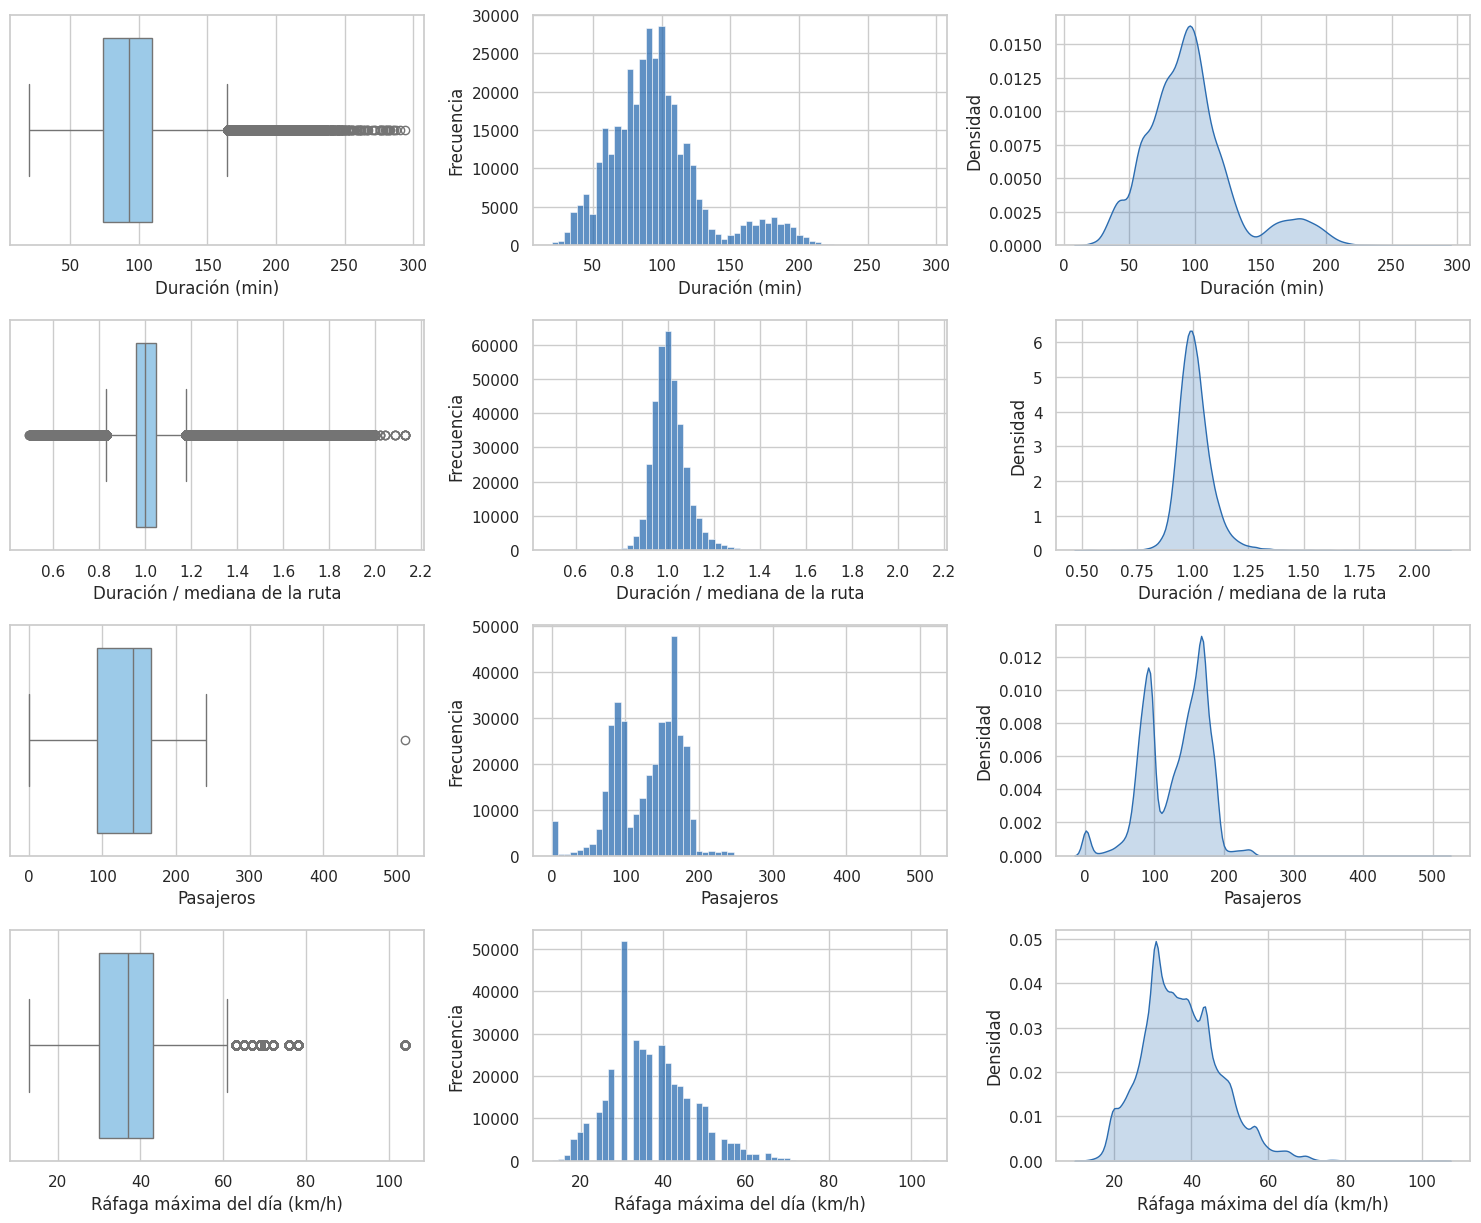

,mean,median,std,skew,"% atípicos (1,5·IQR)"
duracion_min,96.16,93.0,34.92,1.02,7.22
dur_rel,1.01,1.0,0.09,2.41,4.22
pasajeros,129.80,141.0,44.02,-0.52,0.00
vto_max,37.25,37.0,9.98,0.60,1.74


Vuelos con 0 pasajeros: 1.12%
dur_rel: P90 global = 1.105


In [17]:
dataset["dur_rel"] = dataset["duracion_min"] / dataset["mediana_ruta_min"]
vars_uni = [("duracion_min", "Duración (min)"), ("dur_rel", "Duración / mediana de la ruta"),
            ("pasajeros", "Pasajeros"), ("vto_max", "Ráfaga máxima del día (km/h)")]

fig, ax = plt.subplots(len(vars_uni), 3, figsize=(15, 3.1 * len(vars_uni)))
for i, (var, tit) in enumerate(vars_uni):
    s = dataset[var].dropna()
    sns.boxplot(x=s, ax=ax[i, 0], color="#90cdf4"); ax[i, 0].set_xlabel(tit)
    sns.histplot(s, bins=60, ax=ax[i, 1], color="#2b6cb0"); ax[i, 1].set_xlabel(tit); ax[i, 1].set_ylabel("Frecuencia")
    sns.kdeplot(s.sample(min(len(s), 50_000), random_state=SEED), fill=True, ax=ax[i, 2], color="#2b6cb0")
    ax[i, 2].set_xlabel(tit); ax[i, 2].set_ylabel("Densidad")
plt.tight_layout(); plt.show()

cols_u = [v for v, _ in vars_uni]
q1, q3 = dataset[cols_u].quantile(.25), dataset[cols_u].quantile(.75)
iqr = q3 - q1
res = dataset[cols_u].agg(["mean", "median", "std", "skew"]).T
res["% atípicos (1,5·IQR)"] = [((dataset[c] < q1[c] - 1.5 * iqr[c]) | (dataset[c] > q3[c] + 1.5 * iqr[c])).mean() * 100 for c in cols_u]
display(res.round(2))
print(f"Vuelos con 0 pasajeros: {(dataset['pasajeros'] == 0).mean():.2%}")
print(f"dur_rel: P90 global = {dataset['dur_rel'].quantile(.9):.3f}")
dataset = dataset.drop(columns="dur_rel")

**Interpretación.**
- **Duración (min):** la distribución es **bimodal**. La masa principal está entre 50 y 130 min y hay una segunda moda entre 150 y 210 min, que corresponde a las rutas largas (AER–USU, AER–GRA). El 7,22 % de "atípicos" según la regla de 1,5·IQR son, en realidad, vuelos de rutas largas: confirma que **la duración absoluta no es comparable entre rutas** y justifica definir el target por ruta.
- **Duración relativa (`dur_rel`):** está muy concentrada en 1 (desvío 0,09) y tiene **asimetría a la derecha** (skew 2,41): la cola larga son vuelos más lentos que lo habitual, que es justamente lo que el target captura (el P90 global de `dur_rel` es 1,105). Aquí la regla del IQR marca un 4,22 % de atípicos que **no deben eliminarse**, porque son la clase de interés.
- **Pasajeros:** también es bimodal, con picos cerca de 90 y de 165 pasajeros, coherente con dos tamaños de aeronave (regionales y de fuselaje angosto). El 1,12 % tiene 0 pasajeros y hay un valor aislado de 511, por encima de la capacidad habitual; son pocos casos y se conservan.
- **Ráfaga máxima:** la mayoría de los días está entre 20 y 60 km/h; los picos del histograma reflejan que el SMN registra valores redondeados. Solo el 1,74 % supera el bigote superior y el máximo (104 km/h) corresponde a un día puntual.

### 6.4 Variables operativas y de calendario vs. target
Se calcula la **tasa de anomalía** (proporción de `duracion_anomala = 1`) por categoría. Como referencia, la tasa global ronda el 9 %: una categoría con una tasa muy distinta es una señal de que la variable aporta información.

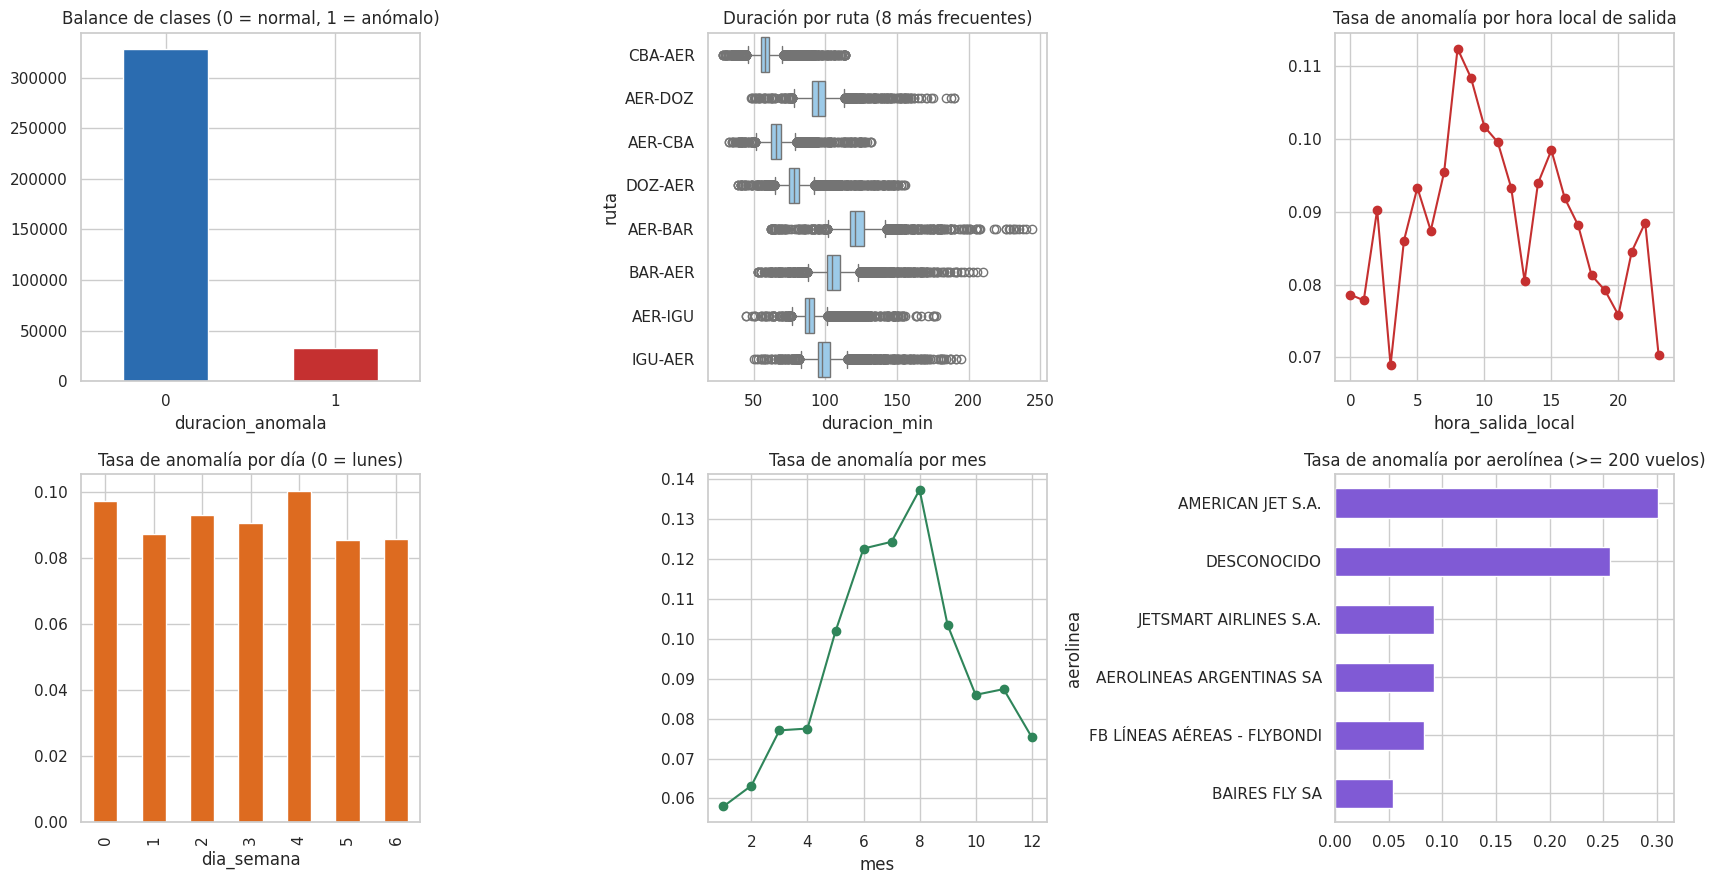

Tasa global de anomalía: 0.092

Por franja horaria:


hora_salida_local,00-05 h,06-11 h,12-17 h,18-23 h
vuelos,21329.000,117411.000,127202.000,95056.000
tasa,0.087,0.102,0.091,0.081


Por sentido:


sentido,llega_AER,sale_AER
vuelos,180079.000,180919.000
tasa,0.098,0.086


Por día de la semana (0 = lunes):


...

mes,1,2,3,4,5,6,7,8,9,10,11,12
vuelos,34498.000,30908.000,37592.000,32382.000,29312.000,28048.000,33716.000,26017.000,25441.000,27606.000,27508.000,27970.000
tasa,0.058,0.063,0.077,0.078,0.102,0.123,0.124,0.137,0.103,0.086,0.087,0.075


Rutas con >= 1000 vuelos: las 5 de menor y las 5 de mayor tasa:


,vuelos,tasa
ruta,,
AER-OSA,1029,0.070
AER-BCA,4057,0.070
AER-SIS,3525,0.075
AER-SVO,1976,0.076
AER-BAR,16757,0.079
CBA-AER,18509,0.104
TRE-AER,3914,0.107
BCA-AER,4069,0.110
SRA-AER,1170,0.110


Aerolíneas con >= 200 vuelos:


,vuelos,tasa
aerolinea,,
BAIRES FLY SA,3331,0.054
FB LÍNEAS AÉREAS - FLYBONDI,47958,0.083
AEROLINEAS ARGENTINAS SA,255411,0.092
JETSMART AIRLINES S.A.,52092,0.092
DESCONOCIDO,936,0.256
AMERICAN JET S.A.,954,0.301


In [18]:
fig, ax = plt.subplots(2, 3, figsize=(17, 9))

dataset["duracion_anomala"].value_counts().sort_index().plot.bar(ax=ax[0, 0], color=["#2b6cb0", "#c53030"])
ax[0, 0].set_title("Balance de clases (0 = normal, 1 = anómalo)"); ax[0, 0].set_xticklabels(["0", "1"], rotation=0)

top = dataset["ruta"].value_counts().head(8).index
sns.boxplot(data=dataset[dataset["ruta"].isin(top)], y="ruta", x="duracion_min", ax=ax[0, 1], color="#90cdf4")
ax[0, 1].set_title("Duración por ruta (8 más frecuentes)")

dataset.groupby("hora_salida_local")["duracion_anomala"].mean().plot(ax=ax[0, 2], marker="o", color="#c53030")
ax[0, 2].set_title("Tasa de anomalía por hora local de salida")

dataset.groupby("dia_semana")["duracion_anomala"].mean().plot.bar(ax=ax[1, 0], color="#dd6b20")
ax[1, 0].set_title("Tasa de anomalía por día (0 = lunes)")

dataset.groupby("mes")["duracion_anomala"].mean().plot(ax=ax[1, 1], marker="o", color="#2f855a")
ax[1, 1].set_title("Tasa de anomalía por mes")

(dataset.groupby("aerolinea")["duracion_anomala"].agg(["mean", "size"]).query("size >= 200")["mean"]
        .sort_values().plot.barh(ax=ax[1, 2], color="#805ad5"))
ax[1, 2].set_title("Tasa de anomalía por aerolínea (>= 200 vuelos)")

plt.tight_layout(); plt.show()

# Tablas con los valores que se comentan en la interpretación
def tasa(col, min_n=0):
    t = dataset.groupby(col, observed=True)["duracion_anomala"].agg(vuelos="size", tasa="mean")
    return t[t["vuelos"] >= min_n]

print(f"Tasa global de anomalía: {dataset['duracion_anomala'].mean():.3f}")
franja = pd.cut(dataset["hora_salida_local"], [-1, 5, 11, 17, 23], labels=["00-05 h", "06-11 h", "12-17 h", "18-23 h"])
print("\nPor franja horaria:"); display(tasa(franja).round(3).T)
print("Por sentido:"); display(tasa("sentido").round(3).T)
print("Por día de la semana (0 = lunes):"); display(tasa("dia_semana").round(3).T)
print("Por mes:"); display(tasa("mes").round(3).T)
t_ruta = tasa("ruta", 1000).sort_values("tasa")
print("Rutas con >= 1000 vuelos: las 5 de menor y las 5 de mayor tasa:"); display(pd.concat([t_ruta.head(5), t_ruta.tail(5)]).round(3))
t_aer = tasa("aerolinea", 200).sort_values("tasa")
print("Aerolíneas con >= 200 vuelos:"); display(t_aer.round(3))

**Interpretación** (tasa global de anomalía: **9,2 %**).
- **Balance de clases:** se ve la proporción aproximada de 10 a 1 descripta en 5.3.
- **Duración por ruta:** cada ruta tiene una caja angosta y una **cola larga a la derecha**, con valores atípicos superiores mucho más numerosos que los inferiores. Es el comportamiento esperado de una demora: puede alargar mucho un vuelo pero no acortarlo de la misma manera.
- **Hora de salida:** es la variable de calendario con más variación. La tasa sube hasta un **pico de ~11 % a las 8–9 h** y baja a ~7 % a las 3 h y a las 23 h. Por franja: 10,2 % entre 6 y 11 h contra 8,1 % entre 18 y 23 h, compatible con mayor congestión en la franja de la mañana.
- **Sentido:** los vuelos que **llegan** a AER son anómalos con más frecuencia (9,8 %) que los que salen (8,6 %), algo coherente con esperas antes de aterrizar en el aeropuerto más congestionado del país.
- **Día de la semana:** diferencias chicas (8,6 % el fin de semana; 9,7 % el lunes y 10,0 % el viernes). Es una señal débil.
- **Mes:** es el patrón **más marcado**. La tasa pasa de **5,8 % en enero a 13,7 % en agosto**: en el invierno (junio a agosto) los vuelos anómalos son más del doble que en el verano.
- **Ruta:** entre las rutas con al menos 1.000 vuelos la tasa va de 7,0 % (AER–OSA, AER–BCA) a 11,1 % (CAT–AER). Las de mayor tasa son todas **llegadas a AER** y las de menor tasa son salidas, lo que refuerza el efecto de `sentido`. Las diferencias son acotadas porque el umbral se calcula por ruta (cada ruta tiene ~10 % de anómalos en entrenamiento por construcción).
- **Aerolínea:** las tres grandes tienen tasas similares (Flybondi 8,3 %, Aerolíneas Argentinas y JetSMART 9,2 %). Se destacan `DESCONOCIDO` (25,6 %) y American Jet (30,1 %), ambas con menos de 1.000 vuelos. En `DESCONOCIDO` la tasa alta probablemente refleja **errores de emparejamiento**, ya que agrupa operadores distintos bajo una misma clave.

### 6.5 Variables meteorológicas vs. target

Tasa de anomalía según día con/sin lluvia:


,size,mean
llueve,,
0,281389,0.085746
1,79609,0.112311


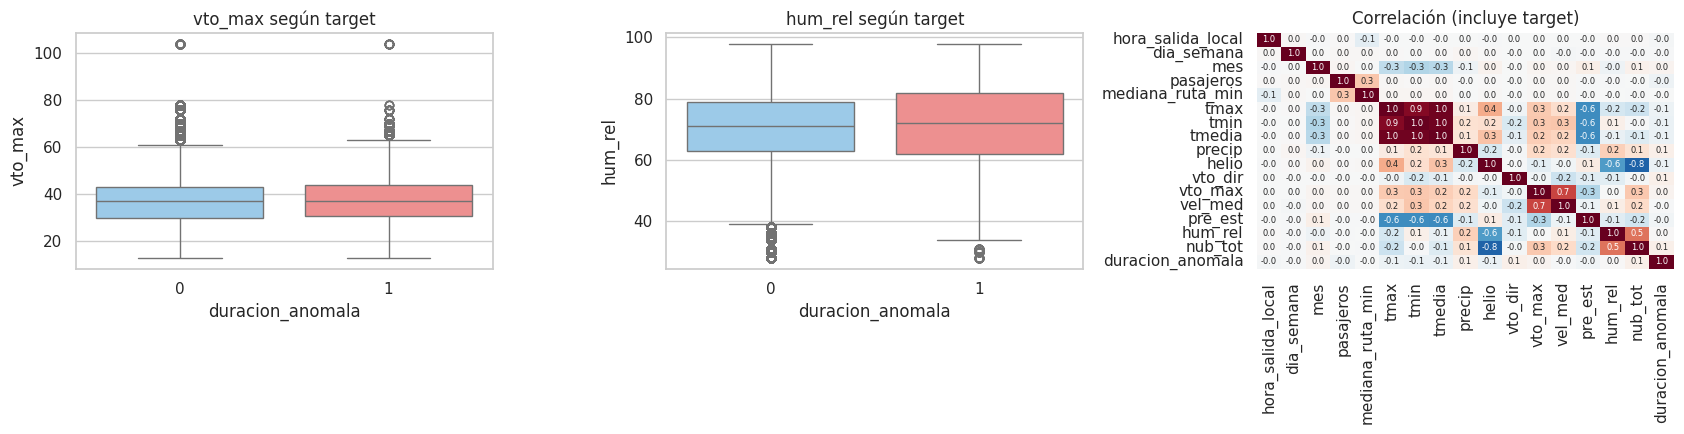

Correlación de Pearson con el target:
helio               -0.064
tmedia              -0.062
tmin                -0.061
tmax                -0.056
nub_tot              0.054
vto_dir              0.053
precip               0.053
pasajeros           -0.050
vto_max              0.035
mes                  0.033
pre_est             -0.033
hora_salida_local   -0.020
vel_med             -0.013
dia_semana          -0.007
hum_rel              0.006
mediana_ruta_min    -0.004

Pares con |r| > 0,8: [('tmax', 'tmin', np.float64(0.91)), ('tmax', 'tmedia', np.float64(0.97)), ('tmin', 'tmedia', np.float64(0.97)), ('helio', 'nub_tot', np.float64(0.81))]

Tasa de anomalía por quintil (Q1 = valores más bajos):


,Q1,Q2,Q3,Q4,Q5
vto_max,0.081,0.093,0.091,0.088,0.114
vel_med,0.094,0.102,0.091,0.088,0.081
hum_rel,0.104,0.077,0.077,0.089,0.111
nub_tot,0.072,0.081,0.095,0.099,0.119
pre_est,0.116,0.087,0.086,0.080,0.089
tmedia,0.120,0.104,0.091,0.072,0.072
helio,0.121,0.105,0.101,0.085,0.061


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, c in zip(ax[:2], ["vto_max", "hum_rel"]):
    sns.boxplot(data=dataset, x="duracion_anomala", y=c, ax=a, palette=["#90cdf4", "#fc8181"])
    a.set_title(f"{c} según target")

dataset["llueve"] = (dataset["precip"].fillna(0) > 0).astype(int)
print("Tasa de anomalía según día con/sin lluvia:")
display(dataset.groupby("llueve")["duracion_anomala"].agg(["size", "mean"]))

cc = ["hora_salida_local", "dia_semana", "mes", "pasajeros", "mediana_ruta_min"] + VARS_CLIMA + ["duracion_anomala"]
sns.heatmap(dataset[cc].corr(), annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=ax[2], cbar=False, annot_kws={"size": 6})
ax[2].set_title("Correlación (incluye target)")
plt.tight_layout(); plt.show()

# Correlación de cada variable con el target, ordenada por valor absoluto
corr_t = dataset[cc].corr()["duracion_anomala"].drop("duracion_anomala").sort_values(key=abs, ascending=False)
print("Correlación de Pearson con el target:"); print(corr_t.round(3).to_string())

# Pares de predictores muy correlacionados entre sí (|r| > 0,8): candidatos a redundancia
m = dataset[cc].drop(columns="duracion_anomala").corr().abs()
pares = [(a, b, round(m.loc[a, b], 2)) for i, a in enumerate(m.columns) for b in m.columns[i + 1:] if m.loc[a, b] > 0.8]
print("\nPares con |r| > 0,8:", pares)

# Tasa de anomalía por quintil de cada variable climática (capta relaciones no lineales)
quint = {}
for c in ["vto_max", "vel_med", "hum_rel", "nub_tot", "pre_est", "tmedia", "helio"]:
    q = pd.qcut(dataset[c], 5, labels=False, duplicates="drop")
    quint[c] = dataset.groupby(q)["duracion_anomala"].mean().values
print("\nTasa de anomalía por quintil (Q1 = valores más bajos):")
display(pd.DataFrame({k: pd.Series(v, index=[f"Q{i+1}" for i in range(len(v))]) for k, v in quint.items()}).T.round(3))
dataset = dataset.drop(columns="llueve")

**Interpretación.**
- **Lluvia:** en los días con lluvia registrada la tasa de anomalía es del **11,2 %**, contra 8,6 % en el resto (+2,6 puntos), con 79.609 vuelos en días de lluvia.
- **Boxplots:** la ráfaga máxima casi no cambia entre vuelos normales y anómalos (medianas en torno a 37 km/h), y la humedad es apenas mayor en los anómalos.
- **Correlación lineal:** todas las correlaciones con el target son **muy bajas** (|r| ≤ 0,064). Las mayores son `helio` (−0,064), las temperaturas (≈ −0,06), `nub_tot`, `precip` y `vto_dir` (≈ +0,05).
- **Tasa por quintil** (capta relaciones que Pearson no ve):
  - Relaciones **monótonas**: con más frío, menos sol y más nubosidad sube la tasa (`tmedia`: 12,0 % en el quintil más frío y 7,2 % en el más cálido; `helio`: 12,1 % → 6,1 %; `nub_tot`: 7,2 % → 11,9 %). La presión baja también se asocia con más anomalías (11,6 % en Q1).
  - Relaciones **no lineales**: `vto_max` es plana del Q1 al Q4 (8,1–9,3 %) y sube recién en el quintil de ráfagas más fuertes (11,4 %): es un efecto de **umbral**. `hum_rel` tiene forma de **U** (10,4 % en Q1, 7,7 % en Q2–Q3 y 11,1 % en Q5), por lo que su correlación lineal es casi nula (0,006) aunque la variable sí aporta información.
- **Redundancias:** `tmax`, `tmin` y `tmedia` están casi perfectamente correlacionadas (|r| entre 0,91 y 0,97), y `helio` con `nub_tot` (|r| = 0,81).
- **Precaución:** la temperatura y la heliofanía están asociadas con el mes (r ≈ −0,3 entre `mes` y la temperatura), de modo que parte de su efecto puede ser estacional. El EDA no permite separar ambos efectos; un modelo multivariado sí puede hacerlo.

### 6.6 Selección de atributos por métodos de filtro: chi-cuadrado y ANOVA
Se mide la relación de cada variable con el target, eligiendo la prueba según el tipo de variable:
- **Chi-cuadrado** para las variables **categóricas**: compara las frecuencias observadas de anómalos y normales en cada categoría con las esperadas si la variable fuera independiente del target. Un chi-cuadrado alto indica asociación. Su valor crece con la cantidad de categorías (los grados de libertad), por lo que se compara teniendo en cuenta los grados de libertad de cada variable.
- **ANOVA** para las variables **numéricas**: compara la media de la variable entre los dos grupos que define el target (vuelos normales y anómalos). Un estadístico F alto indica que las medias difieren. En la Unidad 1 se presenta con los grupos definidos por una variable de entrada; aquí los grupos son las clases del target, pero la prueba es la misma.

Se calcula **solo con el período de entrenamiento**, para no usar información del test. Con cientos de miles de vuelos casi cualquier diferencia resulta estadísticamente significativa (p-valor < 0,05), por lo que se mira sobre todo el **tamaño** del estadístico para ordenar las variables.

Chi-cuadrado (variables categóricas y de calendario):


,categorías,chi-cuadrado,gl,p-valor
variable,,,,
aeronave,88,4111.3,87,0.0000
mes,12,2201.5,11,0.0000
aerolinea,39,979.9,38,0.0000
hora_salida_local,24,378.6,23,0.0000
ruta,76,128.0,75,0.0001
dia_semana,7,120.8,6,0.0000
fin_de_semana,2,81.4,1,0.0000
destino,39,78.7,38,0.0001
origen,39,49.9,38,0.0929


ANOVA (variables numéricas):


,F (ANOVA),p-valor,media normales,media anómalos
variable,,,,
helio,1229.1,0.0000,7.35,6.42
nub_tot,1103.3,0.0000,3.76,4.28
tmedia,1096.8,0.0000,18.56,17.38
tmin,987.9,0.0000,15.21,14.10
tmax,966.2,0.0000,22.25,21.06
vto_dir,731.7,0.0000,15.42,17.12
pasajeros,723.6,0.0000,129.58,121.96
vto_max,342.3,0.0000,37.25,38.45
pre_est,277.9,0.0000,1015.53,1014.87


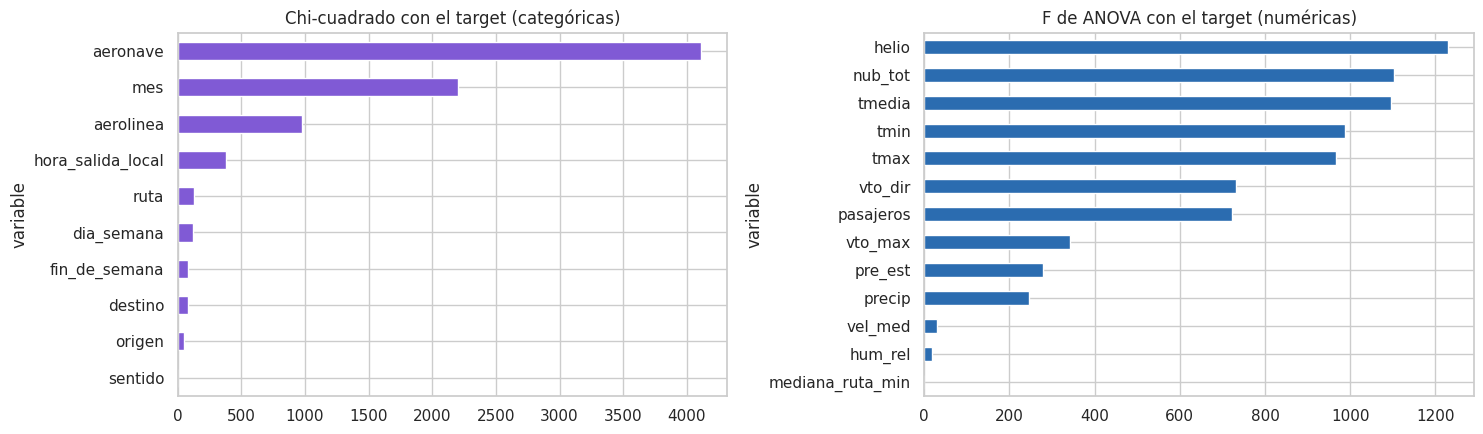

In [20]:
from scipy.stats import chi2_contingency
from sklearn.feature_selection import f_classif

entren = dataset[dataset["es_train"] == 1]
cand_cat = ["ruta", "sentido", "aerolinea", "aeronave", "origen", "destino", "dia_semana", "mes", "hora_salida_local", "fin_de_semana"]
cand_num = ["pasajeros", "mediana_ruta_min"] + VARS_CLIMA

# Chi-cuadrado: tabla de contingencia categoría x target
filas = []
for c in cand_cat:
    chi2, p, gl, _ = chi2_contingency(pd.crosstab(entren[c], entren["duracion_anomala"]))
    filas.append({"variable": c, "categorías": entren[c].nunique(), "chi-cuadrado": chi2, "gl": gl, "p-valor": p})
chi = pd.DataFrame(filas).set_index("variable").sort_values("chi-cuadrado", ascending=False)
print("Chi-cuadrado (variables categóricas y de calendario):")
display(chi.round({"chi-cuadrado": 1, "p-valor": 4}))

# ANOVA: compara la media de cada numérica entre vuelos normales y anómalos (se omiten los nulos de cada variable)
filas = []
for c in cand_num:
    s = entren[[c, "duracion_anomala"]].dropna()
    f, p = f_classif(s[[c]], s["duracion_anomala"])
    filas.append({"variable": c, "F (ANOVA)": f[0], "p-valor": p[0],
                  "media normales": s.loc[s["duracion_anomala"] == 0, c].mean(),
                  "media anómalos": s.loc[s["duracion_anomala"] == 1, c].mean()})
anova = pd.DataFrame(filas).set_index("variable").sort_values("F (ANOVA)", ascending=False)
print("ANOVA (variables numéricas):")
display(anova.round({"F (ANOVA)": 1, "p-valor": 4, "media normales": 2, "media anómalos": 2}))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
chi["chi-cuadrado"].sort_values().plot.barh(ax=ax[0], color="#805ad5"); ax[0].set_title("Chi-cuadrado con el target (categóricas)")
anova["F (ANOVA)"].sort_values().plot.barh(ax=ax[1], color="#2b6cb0"); ax[1].set_title("F de ANOVA con el target (numéricas)")
plt.tight_layout(); plt.show()

**Interpretación.**
- **Chi-cuadrado (categóricas):** la asociación más fuerte con el target es la de `aeronave` (4.111), seguida por `mes` (2.202), `aerolinea` (980) y `hora_salida_local` (379).
- Para comparar entre variables hay que tener en cuenta los grados de libertad (gl): si una variable fuera independiente del target, su chi-cuadrado rondaría su cantidad de gl. `ruta` obtiene 128 con 75 gl: hay asociación (p = 0,0001), pero **débil**. Es esperable, porque el umbral del target se calcula por ruta y todas las rutas quedan con alrededor del 10 % de anómalos.
- **Sin asociación** en el período de entrenamiento: `sentido` (chi-cuadrado 0,6; p = 0,43) y `origen` (p = 0,09). En el EDA (6.4) los vuelos que llegan a AER tenían más anomalías, pero esa diferencia no aparece en el período de entrenamiento: la relación **cambió con el tiempo**.
- **ANOVA (numéricas):** las variables cuya media más difiere entre vuelos normales y anómalos son las del clima asociado al invierno: `helio` (F = 1.229; 7,35 contra 6,42 horas de sol), `nub_tot` (1.103; 3,76 contra 4,28 octavos) y las tres temperaturas (≈ 1.000; 18,6 °C contra 17,4 °C de media). Les siguen `vto_dir` (732), `pasajeros` (724; 130 contra 122) y `vto_max` (342).
- `mediana_ruta_min` **no** muestra diferencia entre clases (F = 0,4; p = 0,51).
- `hum_rel` obtiene un F bajo (19,5) aunque en 6.5 mostró una relación en forma de U. ANOVA compara medias y, como la tasa sube en los dos extremos, las medias de ambas clases quedan casi iguales (70,8 contra 71,1). Igual que Pearson, no detecta relaciones no lineales.
- En todos los casos las diferencias entre clases son **chicas** en valor absoluto: ninguna variable separa por sí sola los vuelos anómalos de los normales.

## 7. Selección de variables
La selección combina tres criterios: **(1) evidencia del EDA** (tasa de anomalía por categoría o quintil y los métodos de filtro de 6.6: chi-cuadrado, ANOVA y correlación de Pearson), **(2) ausencia de fuga de información** (solo variables conocidas antes del despegue) y **(3) no redundancia** (Unidad 1: variables con |r| superior a 0,7 aportan información repetida).

| Variable | Evidencia | Decisión |
|---|---|---|
| `mes` | Tasa de 5,8 % (enero) a 13,7 % (agosto); chi-cuadrado 2.202 (2.º) | **Incluir** |
| `hora_salida_local` | Tasa de ~7 % a ~11 % según la hora; chi-cuadrado 379 | **Incluir** |
| `dia_semana` | Tasa de 8,6 % a 10,0 %; chi-cuadrado 121 con 6 gl | Incluir (señal débil) |
| `fin_de_semana` | Derivada de `dia_semana` | Excluir (redundante) |
| `sentido` | Chi-cuadrado 0,6 (p = 0,43) en entrenamiento; además, la ruta ya indica si el vuelo sale o llega | Excluir |
| `ruta` | Chi-cuadrado 128 con 75 gl (asociación débil por construcción del target); tasas de 7,0 % a 11,1 % | Incluir (permite combinar ruta y clima) |
| `origen`, `destino` | Se deducen de `ruta`; `origen` sin asociación (p = 0,09) | Excluir |
| `mediana_ruta_min` | Un valor por ruta; ANOVA F = 0,4 (p = 0,51) | Excluir |
| `aerolinea` | Chi-cuadrado 980; `DESCONOCIDO` con 25,6 % | Incluir |
| `aeronave` | Chi-cuadrado 4.111 (1.º) | Incluir, vigilando la calidad del emparejamiento |
| `pasajeros` | ANOVA F = 724 (130 contra 122 pasajeros) | Incluir |
| `tmedia` | ANOVA F = 1.097; tasa de 12,0 % a 7,2 % por quintil | **Incluir** |
| `tmax`, `tmin` | \|r\| ≥ 0,91 con `tmedia` | Excluir (redundantes) |
| `helio` | ANOVA F = 1.229 (1.º); 21,6 % de nulos | Incluir (el modelo maneja `NaN`) |
| `nub_tot` | ANOVA F = 1.103; \|r\| = 0,81 con `helio` | Incluir (sin nulos, complementa a `helio`) |
| `precip` + `llueve` (derivada) | ANOVA F = 245; 11,2 % con lluvia contra 8,6 % sin lluvia | Incluir ambas |
| `vto_max` | ANOVA F = 342; efecto umbral en el quintil superior | **Incluir** |
| `vel_med` | ANOVA F = 31 (débil); r = 0,7 con `vto_max` | Incluir (señal débil) |
| `vto_dir` | ANOVA F = 732; variable circular (1 a 36) | Reemplazar por seno y coseno |
| `pre_est` | ANOVA F = 278; presión baja con 11,6 % | Incluir |
| `hum_rel` | ANOVA F = 19,5, pero relación en U (6.5) que ANOVA no capta | Incluir (efecto no lineal) |
| Ventanas móviles | Se construyen y justifican en 12.1 | Incluir |
| `duracion_min`, `p90_ruta_min` | Definen el target | **Excluir (fuga)** |
| `dt_salida`, `dt_llegada`, `es_train` | Identifican el momento o la partición | Excluir; se usan para ordenar y particionar |

**Reducción de dimensionalidad.** No se aplica PCA. PCA es útil cuando hay muchas variables numéricas correlacionadas; aquí la única redundancia fuerte (las tres temperaturas) se resuelve quedándose con `tmedia`, el modelo trabaja con 20 predictores, y las componentes principales, al ser combinaciones lineales, impedirían explicar qué variable influye en cada predicción.

La celda siguiente deja el conjunto de variables explícito para la etapa de modelado.

In [21]:
# Conjunto de variables que se usará en el modelado (decisión justificada en la tabla anterior)
FEATURES_CAT = ["ruta", "aerolinea", "aeronave"]
FEATURES_NUM = ["hora_salida_local", "dia_semana", "mes", "pasajeros",
                "tmedia", "precip", "helio", "vto_max", "vel_med", "pre_est", "hum_rel", "nub_tot"]
FEATURES_DERIVADAS = ["vto_dir_sin", "vto_dir_cos", "llueve"]   # se calculan en la Sección 12
FEATURES_TEMPORALES = ["tasa_ruta_7d", "tasa_aer_dia_prev"]   # ventanas móviles, Sección 12.1
EXCLUIDAS = {
    "dt_salida, dt_llegada": "identifican el momento; se usan solo para ordenar y particionar",
    "origen, destino": "redundantes con ruta",
    "sentido": "sin asociación con el target en entrenamiento (chi-cuadrado, p = 0,43) y redundante con ruta",
    "mediana_ruta_min": "un único valor por ruta (redundante con ruta) y sin diferencia entre clases (ANOVA)",
    "tmax, tmin": "redundantes con tmedia (|r| >= 0,91)",
    "fin_de_semana": "derivada de dia_semana",
    "vto_dir": "circular; se reemplaza por seno y coseno",
    "duracion_min, p90_ruta_min": "fuga de información: definen el target",
    "es_train": "solo indica la partición",
}
TARGET = "duracion_anomala"
print(f"Predictores: {len(FEATURES_CAT)} categóricos + {len(FEATURES_NUM)} numéricos + {len(FEATURES_DERIVADAS)} derivados"
      f" + {len(FEATURES_TEMPORALES)} temporales")
display(pd.DataFrame(EXCLUIDAS.items(), columns=["variable excluida", "motivo"]))

Predictores: 3 categóricos + 12 numéricos + 3 derivados + 2 temporales


,variable excluida,motivo
0,"dt_salida, dt_llegada",identifican el momento; se usan solo para orde...
1,"origen, destino",redundantes con ruta
2,sentido,sin asociación con el target en entrenamiento ...
3,mediana_ruta_min,un único valor por ruta (redundante con ruta) ...
4,"tmax, tmin","redundantes con tmedia (|r| >= 0,91)"
5,fin_de_semana,derivada de dia_semana
6,vto_dir,circular; se reemplaza por seno y coseno
7,"duracion_min, p90_ruta_min",fuga de información: definen el target
8,es_train,solo indica la partición


## 8. Particionamiento de los datos
Los vuelos forman una **serie temporal**: si se mezclaran al azar, el modelo vería vuelos del mismo día (con el mismo clima) en entrenamiento y en prueba, y la evaluación sería optimista. Por eso la partición es **cronológica**:

1. **Test (20 % más reciente):** queda fuera de todo, incluido el cálculo de los umbrales P90 del target (Sección 5.2).
2. **Entrenamiento (80 % más antiguo):** se usa para ajustar el modelo. Dentro de él, el **último 20 %** se reserva como **validación** para ajustar hiperparámetros y el umbral de decisión.
3. Para una estimación más estable se usará además **validación cruzada temporal** (`TimeSeriesSplit`, 5 bloques). Es el esquema que la clase de series temporales llama **expanding window**: cada bloque entrena con todo el pasado disponible (la ventana de entrenamiento crece) y valida con el período inmediatamente siguiente, de modo que nunca se entrena con datos del futuro.

,vuelos,desde,hasta,tasa_anomalia,% del total
1_entrenamiento,231074,2021-03-15 21:07:00,2025-02-12 15:43:00,0.085,64.010
2_validación,57769,2025-02-12 15:48:00,2025-09-25 20:44:00,0.113,16.003
3_test,72155,2025-09-25 20:45:00,2026-08-01 02:03:00,0.097,19.988


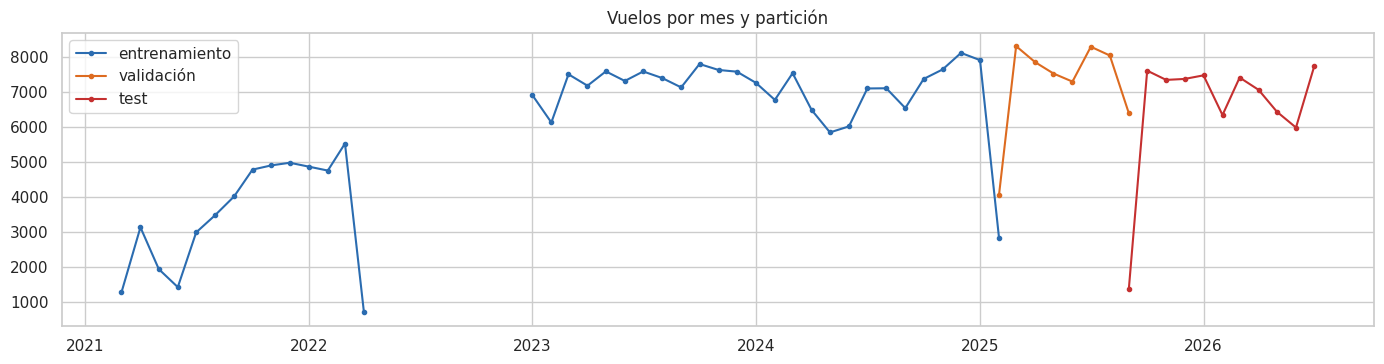

Validación cruzada temporal sobre entrenamiento + validación (5 bloques):
  bloque 1: entrena 2021-03-15 -> 2022-04-01 (48,143) | valida 2022-04-01 -> 2023-07-21 (48,140) | tasa val. 0.089
  bloque 2: entrena 2021-03-15 -> 2023-07-21 (96,283) | valida 2023-07-21 -> 2024-02-03 (48,140) | tasa val. 0.100
  bloque 3: entrena 2021-03-15 -> 2024-02-03 (144,423) | valida 2024-02-03 -> 2024-09-09 (48,140) | tasa val. 0.099
  bloque 4: entrena 2021-03-15 -> 2024-09-09 (192,563) | valida 2024-09-09 -> 2025-03-21 (48,140) | tasa val. 0.081
  bloque 5: entrena 2021-03-15 -> 2025-03-21 (240,703) | valida 2025-03-21 -> 2025-09-25 (48,140) | tasa val. 0.115

Rutas del test sin vuelos en entrenamiento: ['AER-SRC', 'SRC-AER']


In [22]:
from sklearn.model_selection import TimeSeriesSplit

dataset = dataset.sort_values("dt_salida").reset_index(drop=True)
corte_val = dataset.loc[dataset["es_train"] == 1, "dt_salida"].quantile(0.80)
particion = pd.Series(np.select([dataset["es_train"] == 0, dataset["dt_salida"] > corte_val],
                                ["3_test", "2_validación"], "1_entrenamiento"), index=dataset.index)

resumen_part = dataset.groupby(particion).agg(vuelos=("dt_salida", "size"), desde=("dt_salida", "min"),
                                              hasta=("dt_salida", "max"), tasa_anomalia=("duracion_anomala", "mean"))
resumen_part["% del total"] = resumen_part["vuelos"] / len(dataset) * 100
display(resumen_part.round(3))

fig, ax = plt.subplots(figsize=(14, 3.8))
mensual = (dataset.groupby([dataset["dt_salida"].dt.to_period("M").dt.to_timestamp(), particion]).size()
                  .unstack().reindex(pd.date_range("2021-03-01", "2026-07-01", freq="MS")))
for col, color in zip(mensual.columns, ["#2b6cb0", "#dd6b20", "#c53030"]):
    ax.plot(mensual.index, mensual[col], marker="o", ms=3, color=color, label=col[2:])
ax.legend()
ax.set_title("Vuelos por mes y partición"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

print("Validación cruzada temporal sobre entrenamiento + validación (5 bloques):")
tr = dataset[dataset["es_train"] == 1]
for k, (i_tr, i_va) in enumerate(TimeSeriesSplit(n_splits=5).split(tr), 1):
    print(f"  bloque {k}: entrena {tr['dt_salida'].iloc[i_tr[0]].date()} -> {tr['dt_salida'].iloc[i_tr[-1]].date()} ({len(i_tr):,})"
          f" | valida {tr['dt_salida'].iloc[i_va[0]].date()} -> {tr['dt_salida'].iloc[i_va[-1]].date()} ({len(i_va):,})"
          f" | tasa val. {tr['duracion_anomala'].iloc[i_va].mean():.3f}")

print("\nRutas del test sin vuelos en entrenamiento:",
      sorted(set(dataset.loc[particion == "3_test", "ruta"]) - set(dataset.loc[particion == "1_entrenamiento", "ruta"])))

**Interpretación.**
- **Entrenamiento:** 231.074 vuelos (64,0 %), del 15/03/2021 al 12/02/2025, con 8,5 % de anómalos.
- **Validación:** 57.769 vuelos (16,0 %), del 12/02/2025 al 25/09/2025, con **11,3 %** de anómalos.
- **Test:** 72.155 vuelos (20,0 %), del 25/09/2025 al 31/07/2026, con 9,7 % de anómalos.
- La tasa de la validación es más alta porque ese período (febrero a septiembre) abarca **todo el invierno de 2025**, la temporada de mayor tasa. No es un error de la partición sino el efecto estacional: por eso el modelo debe incluir `mes` y la evaluación debe mirar varios períodos.
- El gráfico muestra el **hueco de abril a diciembre de 2022** dentro del entrenamiento. En la validación cruzada temporal, el bloque 1 valida justamente sobre un período que atraviesa ese hueco (abril de 2022 a julio de 2023).
- Las tasas de los 5 bloques van de **8,1 % a 11,5 %**. Esa variación anticipa que las métricas cambiarán según el período, por lo que se informará el **promedio y el desvío** entre bloques.
- Dos rutas (AER–SRC y SRC–AER) aparecen en el test pero no en el tramo de entrenamiento; sí están en la validación, por lo que el modelo final (entrenado con entrenamiento + validación) las verá.
- Los umbrales P90 se calcularon con entrenamiento + validación; el **test queda totalmente aislado** de la definición del target y del ajuste del modelo.

## 9. Síntesis de hallazgos del EDA

**1. El problema está bien definido a partir de una limitación real de la fuente.** ANAC no tiene número de vuelo ni horario programado, y la matrícula existe solo en 2026. Los vuelos se reconstruyeron emparejando despegues y aterrizajes: se emparejó el 93,9 % de los despegues y se descartó el 0,61 % de duraciones imposibles.

**2. La duración absoluta no es comparable entre rutas, pero la relativa sí.** La duración es bimodal por la mezcla de rutas cortas y largas, mientras que el cociente duración/mediana se concentra en 1 con cola derecha. Por eso el target se define con el **P90 de cada ruta**, que en promedio equivale a 1,13 veces su mediana.

**3. La clase positiva es minoritaria:** 9,04 % en entrenamiento y 9,65 % en prueba. La *accuracy* no sirve como métrica y el desbalance se tratará solo en entrenamiento.

**4. La estacionalidad es la señal más fuerte.** La tasa de anomalía pasa de 5,8 % en enero a 13,7 % en agosto y se refleja en las variables asociadas al invierno: menos temperatura, menos sol y más nubosidad aumentan la tasa.

**5. El contexto operativo aporta señal moderada:** la mañana (pico de ~11 % a las 8–9 h) y las llegadas a AER (9,8 % contra 8,6 % de las salidas) concentran más anomalías.

**6. El clima actúa de forma no lineal.** La lluvia sube la tasa de 8,6 % a 11,2 %; el viento solo influye en los días de ráfagas más fuertes y la humedad tiene forma de U. Las correlaciones lineales son todas menores a 0,07 en valor absoluto, pero las tasas por quintil y las pruebas de chi-cuadrado y ANOVA muestran dependencia.

**7. Ninguna variable predice sola.** Las correlaciones lineales son todas menores a 0,07 en valor absoluto y, aunque chi-cuadrado y ANOVA detectan asociación en casi todas las variables, las diferencias entre clases son chicas (por ejemplo, 7,35 contra 6,42 horas de sol en promedio, 6.6): el valor del modelo estará en **combinar** estacionalidad, horario, ruta y clima.

### ¿Es viable un modelo predictivo?
**Sí, con expectativas acotadas.** Hay señales consistentes (mes, hora y clima) pero débiles por separado, y relaciones no lineales y de umbral. Esto favorece un modelo de **árboles en ensamble** frente a uno lineal y obliga a evaluar con métricas para la clase minoritaria y con partición temporal (Sección 8). Las limitaciones principales son el ~1 % de duraciones dudosas por el emparejamiento aproximado, el clima diario de una única estación y el hueco de datos de 2022.

## 10. Acceso al dataset limpio

In [23]:
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
dataset.to_csv(OUT_PATH, index=False)
print("Dataset limpio guardado en:", OUT_PATH, "| filas:", len(dataset), "| columnas:", dataset.shape[1])

# Si los archivos están en el almacenamiento temporal de Colab, copiar también a Drive para no perder el resultado
if not DATA_DIR.startswith("/content/drive") and os.path.isdir("/content/drive/MyDrive"):
    destino = "/content/drive/MyDrive/TP_vuelos"
    os.makedirs(destino, exist_ok=True)
    dataset.to_csv(os.path.join(destino, "dataset_limpio.csv"), index=False)
    print("Copia también guardada en Drive:", destino)

Dataset limpio guardado en: /content/repo/data/dataset_limpio.csv | filas: 360998 | columnas: 29


**Enlace al dataset limpio:** https://drive.google.com/file/d/1e66bfYCUSbqW0W7O9dE64ejf-iGkUrTr/view?usp=sharing

Lectura directa desde el enlace compartido:
```python
import pandas as pd
dataset = pd.read_csv("https://drive.google.com/uc?id=1e66bfYCUSbqW0W7O9dE64ejf-iGkUrTr", parse_dates=["dt_salida", "dt_llegada"])
```
La columna `es_train` permite reproducir la partición de la Sección 8 sin recalcularla.

## 11. Modelo de Aprendizaje Automático propuesto

### Tipo de problema
Clasificación supervisada **binaria y desbalanceada** (9,0 % de clase positiva en entrenamiento), con los predictores seleccionados en la Sección 7: categóricos (`ruta`, `aerolinea`, `aeronave`), de calendario (`mes`, `hora_salida_local`, `dia_semana`), `pasajeros`, meteorológicos y de ventana móvil (12.1), algunos con valores faltantes (`helio` 21,6 %, `precip` 66,3 %).

### Modelo elegido: Gradient Boosting sobre árboles de decisión (`HistGradientBoostingClassifier`)
Es un ensamble de árboles de decisión entrenados en secuencia, donde cada árbol corrige los errores de los anteriores.

| Criterio | Evidencia del EDA | Por qué encaja |
|---|---|---|
| Relaciones no lineales y de umbral | Viento con efecto solo en el quintil superior; humedad en U (6.5) | Los árboles cortan por umbrales sin suponer linealidad. |
| Interacciones | Señales débiles por separado: correlaciones menores a 0,07 (6.5) | Combina mes × hora × ruta × clima. |
| Valores faltantes | `helio` y `precip` con nulos (6.2) | Maneja `NaN` de forma nativa, sin imputar. |
| Datos tabulares mixtos | 3 categóricas + 12 numéricas + 3 derivadas + 2 temporales (7) | Soporta categóricas de forma nativa. |
| Desbalance | 9,0 % positivos (5.3) | Se combina con undersampling del entrenamiento (Unidad 6). |
| Escala | 360.998 vuelos | La versión por histogramas es rápida con cientos de miles de filas. |
| Interpretabilidad | Hay que explicar las causas a operaciones | Permite medir qué variables influyen más en el modelo (Unidad 2). |

### Protocolo de evaluación
- **Partición temporal** de la Sección 8: entrenamiento, validación y test cronológicos, más validación cruzada temporal (*expanding window*) de 5 bloques para elegir los hiperparámetros, informando promedio y desvío.
- **Métricas:** matriz de confusión, **sensibilidad (recall), especificidad, precisión y F1** de la clase anómala, y el área bajo la **curva ROC** (ROC-AUC). La *accuracy* no sirve: con 9 % de positivos, predecir siempre "normal" da ~91 %.
- **Desbalance:** undersampling aplicado **solo al entrenamiento**.
- El **umbral de decisión** se elige sobre la validación y se aplica sin cambios al test.
- Como **referencia** se informa el valor que obtendría una predicción sin información (por ejemplo, ROC-AUC = 0,5). No es un modelo alternativo: es el piso para saber si el modelo aprende algo.

### Limitaciones
- **Emparejamiento aproximado:** sin número de vuelo, y con matrícula solo en 2026, los vuelos se reconstruyen por ruta, aerolínea y modelo. Tras los filtros, alrededor del 1 % de los vuelos conserva una duración dudosa (0,56 % por debajo de 0,8 veces la mediana y 0,49 % por encima de 1,5 veces, Sección 4.4).
- **Cobertura:** el archivo de 2022 termina el 04/04/2022, por lo que el entrenamiento tiene un hueco de abril a diciembre de 2022.
- **Clima diario y solo de AER:** no distingue el momento del día en que llovió o hubo viento, no incluye visibilidad ni el clima en el otro aeropuerto de la ruta.
- **Target relativo:** mide duración inusual respecto del histórico de la ruta, no demora respecto del horario programado.


## 12. Preparación de los datos para el modelado
Se construye la matriz de predictores con las variables elegidas en la Sección 7, se agregan las tres variables derivadas y se separan las particiones de la Sección 8.

El preprocesamiento es mínimo porque el gradient boosting no lo necesita:
- **Categóricas:** se codifican con un número por categoría (codificación ordinal) y el modelo las trata como **categóricas nativas**, sin suponer un orden entre ellas.
- **Numéricas:** no se escalan (los árboles no dependen de la escala) ni se imputan (el modelo maneja `NaN` de forma nativa).

La codificación se ajusta **dentro de un `Pipeline`**, solo con los datos de entrenamiento de cada partición. Las categorías que no aparecen en entrenamiento (por ejemplo, una ruta nueva) se tratan como desconocidas.

Además se construyen dos **variables temporales**, que no forman parte del dataset limpio porque dependen de la partición y del target de días anteriores.

### 12.1 Variables temporales: ventanas móviles

| Técnica | Decisión | Motivo |
|---|---|---|
| Variables de calendario | Ya incluidas | `mes`, `dia_semana` y `hora_salida_local` (Sección 7). |
| **Ventanas móviles** | **Se agregan** | Resumen el comportamiento reciente: si una ruta viene con muchas anomalías, es probable que siga así (autocorrelación). |
| Rezagos (lags) | Incluidos en la ventana | El rezago de 1 día de la tasa global equivale a una ventana de 1 día. |
| Diferencias | No se aplican | Sirven para quitar tendencia de una serie continua; aquí el target es binario por vuelo y la estacionalidad se capta con `mes`. |
| Feriados | No se agregan | No hay una fuente de feriados en los datos del trabajo; queda como mejora futura. |

Se construyen dos variables, usando **solo días anteriores** al del vuelo (en hora local), para que estén disponibles antes de despegar y no haya fuga de información:
- `tasa_ruta_7d`: proporción de vuelos anómalos de la **misma ruta** en los **7 días anteriores**.
- `tasa_aer_dia_prev`: proporción de vuelos anómalos de **todo AER** el **día anterior** (congestión general).

In [24]:
fecha_local = (dataset["dt_salida"] + UTC_A_LOCAL).dt.normalize()
base = pd.DataFrame({"ruta": dataset["ruta"], "fecha": fecha_local, "y": dataset[TARGET]})

# Ventana móvil por ruta: suma de anómalos / vuelos de los 7 días previos (shift(1) excluye el día del vuelo)
partes = []
for ruta, g in base.groupby("ruta"):
    d = g.groupby("fecha")["y"].agg(["sum", "size"]).resample("D").sum()
    tasa = d["sum"].rolling(7, min_periods=1).sum().shift(1) / d["size"].rolling(7, min_periods=1).sum().shift(1)
    partes.append(pd.DataFrame({"ruta": ruta, "fecha": d.index, "tasa_ruta_7d": tasa.values}))
ventana_ruta = pd.concat(partes)

# Rezago de 1 día de la tasa global de AER
ventana_aer = (base.groupby("fecha")["y"].mean().resample("D").mean().shift(1)
                   .rename("tasa_aer_dia_prev").reset_index())

temporales = (base.reset_index().merge(ventana_ruta, on=["ruta", "fecha"], how="left")
                  .merge(ventana_aer, on="fecha", how="left").set_index("index"))
print("Nulos (primeros días de cada ruta o días sin vuelos previos):", temporales[FEATURES_TEMPORALES].isna().sum().to_dict())
display(temporales[FEATURES_TEMPORALES].describe().T.round(3))

# Evidencia: tasa de anomalía por quintil de cada variable (solo período de entrenamiento)
entren_idx = dataset.index[dataset["es_train"] == 1]
quint = {}
for c in FEATURES_TEMPORALES:
    q = pd.qcut(temporales.loc[entren_idx, c].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
    quint[c] = dataset.loc[entren_idx, TARGET].groupby(q, observed=True).mean()
print("Tasa de anomalía por quintil (Q1 = valores más bajos; los empates se reparten por orden), período de entrenamiento:")
display(pd.DataFrame(quint).T.round(3))

Nulos (primeros días de cada ruta o días sin vuelos previos): {'tasa_ruta_7d': 571, 'tasa_aer_dia_prev': 231}


,count,mean,std,min,25%,50%,75%,max
tasa_ruta_7d,360427.0,0.091,0.103,0.0,0.015,0.062,0.130,1.0
tasa_aer_dia_prev,360767.0,0.092,0.066,0.0,0.045,0.072,0.123,0.5


Tasa de anomalía por quintil (Q1 = valores más bajos; los empates se reparten por orden), período de entrenamiento:


,Q1,Q2,Q3,Q4,Q5
tasa_ruta_7d,0.057,0.064,0.080,0.102,0.149
tasa_aer_dia_prev,0.059,0.068,0.082,0.097,0.147


**Interpretación.**
- Las dos variables tienen muy pocos faltantes: 571 vuelos sin `tasa_ruta_7d` (primeros días de cada ruta) y 231 sin `tasa_aer_dia_prev` (primer día de cada tramo de datos). El modelo los maneja como `NaN`.
- `tasa_ruta_7d` tiene una media de 9,1 %, la misma que la tasa global, pero varía mucho entre rutas y semanas (mediana 6,2 %; percentil 75: 13,0 %).
- **Las dos variables muestran una relación fuerte y creciente con el target.** Cuando la ruta viene de una semana con pocas anomalías (Q1), la tasa del vuelo es de **5,7 %**; cuando viene de una semana con muchas (Q5), es de **14,9 %**, 2,6 veces más. Con la tasa de AER del día anterior el patrón es casi igual (5,9 % → 14,7 %).
- Es la **autocorrelación** de la que habla la clase de series temporales: las anomalías no ocurren aisladas, sino que se agrupan en el tiempo. El rango de estas variables es comparable al del `mes` (5,8 % → 13,7 %, 6.4), la señal más fuerte del EDA.

### 12.2 Matriz de predictores y particiones

In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
try:
    from imblearn.pipeline import Pipeline as PipelineImb          # pipeline que admite remuestreo
    from imblearn.under_sampling import RandomUnderSampler
except ImportError:
    !pip install -q imbalanced-learn
    from imblearn.pipeline import Pipeline as PipelineImb
    from imblearn.under_sampling import RandomUnderSampler

def preparar(df):
    """Predictores de la Sección 7 + variables derivadas."""
    X = df[FEATURES_CAT + FEATURES_NUM].copy()
    angulo = 2 * np.pi * df["vto_dir"] / 36              # dirección del viento en decenas de grados -> radianes
    X["vto_dir_sin"], X["vto_dir_cos"] = np.sin(angulo), np.cos(angulo)
    X["llueve"] = (df["precip"].fillna(0) > 0).astype(int)
    X[FEATURES_TEMPORALES] = temporales.loc[df.index, FEATURES_TEMPORALES]
    return X

X_all, y_all = preparar(dataset), dataset[TARGET]
NUM = FEATURES_NUM + FEATURES_DERIVADAS + FEATURES_TEMPORALES
m_tr, m_va, m_te = (particion == "1_entrenamiento"), (particion == "2_validación"), (particion == "3_test")
m_trva = m_tr | m_va

# Entrenamiento + validación, en orden cronológico, para la validación cruzada temporal
X_trva, y_trva = X_all[m_trva].reset_index(drop=True), y_all[m_trva].reset_index(drop=True)

prep_hgb = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan, encoded_missing_value=np.nan), FEATURES_CAT),
    ("num", "passthrough", NUM)])

resumen_X = pd.DataFrame({
    "vuelos": [m_tr.sum(), m_va.sum(), m_te.sum()],
    "tasa_anomalia": [y_all[m_tr].mean(), y_all[m_va].mean(), y_all[m_te].mean()]},
    index=["entrenamiento", "validación", "test"])
display(resumen_X.round(3))
print("Predictores:", X_all.shape[1], "->", list(X_all.columns))
print("Nulos por predictor:", X_all.isna().sum()[lambda s: s > 0].to_dict())

,vuelos,tasa_anomalia
entrenamiento,231074,0.085
validación,57769,0.113
test,72155,0.097


Predictores: 20 -> ['ruta', 'aerolinea', 'aeronave', 'hora_salida_local', 'dia_semana', 'mes', 'pasajeros', 'tmedia', 'precip', 'helio', 'vto_max', 'vel_med', 'pre_est', 'hum_rel', 'nub_tot', 'vto_dir_sin', 'vto_dir_cos', 'llueve', 'tasa_ruta_7d', 'tasa_aer_dia_prev']
Nulos por predictor: {'precip': 239482, 'helio': 77994, 'tasa_ruta_7d': 571, 'tasa_aer_dia_prev': 231}


**Interpretación.**
- Las tres particiones mantienen los tamaños y las tasas de la Sección 8: entrenamiento con 231.074 vuelos (8,5 % anómalos), validación con 57.769 (11,3 %) y test con 72.155 (9,7 %).
- La matriz de predictores tiene **20 columnas**: las 3 categóricas y las 12 numéricas de la Sección 7, las 3 derivadas (`vto_dir_sin`, `vto_dir_cos`, `llueve`) y las 2 temporales de 12.1.
- Solo `precip`, `helio` y, en muy pocos casos, las variables temporales tienen faltantes; el modelo los recibe sin imputar.

## 13. Entrenamiento y ajuste de hiperparámetros

**Protocolo.** Los hiperparámetros del modelo se eligen con **validación cruzada temporal** (`TimeSeriesSplit`, 5 bloques) sobre entrenamiento + validación, tal como se definió en la Sección 8: cada bloque entrena con el pasado y valida con el período siguiente. El test no participa en ninguna decisión.

**Métrica para elegir hiperparámetros.** Se usa el **área bajo la curva ROC (ROC-AUC)**. El F1 para datos desbalanceados, depende del umbral de decisión, que todavía no se eligió. La curva ROC grafica la sensibilidad contra la tasa de falsos positivos (1 − especificidad) para **todos** los umbrales posibles, y su área resume el desempeño sin depender de uno en particular: 0,5 equivale a predecir al azar y 1 a clasificar todo bien. También se informa el F1 con el umbral por defecto (0,5).

**Desbalance (Unidad 6).** Se aplica **undersampling**: en cada entrenamiento se eliminan al azar vuelos normales hasta igualar la cantidad de anómalos. El remuestreo va dentro del pipeline, por lo que se aplica **solo a los datos con los que se entrena** y nunca a la validación ni al test.

### 13.1 Tratamiento del desbalance
Se evalúan las dos formas de compensar el desbalance **sobre el mismo modelo** y con la misma validación cruzada temporal: **undersampling** y ponderar las clases con `class_weight="balanced"`. No es una comparación de modelos: es una decisión de preprocesamiento.

In [26]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_validate

tscv = TimeSeriesSplit(n_splits=5)
METRICAS = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision"}

def gb(**kw):
    return HistGradientBoostingClassifier(categorical_features=list(range(len(FEATURES_CAT))), learning_rate=0.05, max_leaf_nodes=15,
                                          max_iter=300, min_samples_leaf=200, early_stopping=False, random_state=SEED, **kw)

variantes = {
    "undersampling": PipelineImb([("prep", prep_hgb), ("under", RandomUnderSampler(random_state=SEED)), ("clf", gb())]),
    "class_weight": PipelineImb([("prep", prep_hgb), ("clf", gb(class_weight="balanced"))]),
}
filas = []
for nombre, m in variantes.items():
    t0 = time.time()
    r = cross_validate(m, X_trva, y_trva, cv=tscv, scoring=METRICAS, n_jobs=2)
    filas.append({"técnica": nombre, "ROC-AUC": r["test_roc_auc"].mean(), "desvío ROC-AUC": r["test_roc_auc"].std(),
                  "F1 (umbral 0,5)": r["test_f1"].mean(), "recall": r["test_recall"].mean(),
                  "precisión": r["test_precision"].mean(), "segundos": time.time() - t0})
display(pd.DataFrame(filas).set_index("técnica").round(3))

,ROC-AUC,desvío ROC-AUC,"F1 (umbral 0,5)",recall,precisión,segundos
técnica,,,,,,
undersampling,0.687,0.017,0.253,0.628,0.159,34.801
class_weight,0.684,0.024,0.260,0.551,0.170,57.155


**Interpretación.**
- Las dos técnicas logran prácticamente **el mismo desempeño**: ROC-AUC de 0,686 ± 0,018 con undersampling y 0,685 ± 0,023 con `class_weight`. La diferencia es mucho menor que el desvío entre bloques.
- Con el umbral 0,5, el undersampling detecta más anomalías (recall 62,7 % contra 55,0 %) a costa de algo menos de precisión (15,9 % contra 17,1 %). Esto pasa porque, al entrenar con clases igualadas, el modelo estima probabilidades más altas que la proporción real de anómalos. No es un problema: el umbral se ajusta en 14.1.
- Se elige **undersampling**: rinde igual, es la técnica que propone el programa (Unidad 6) y tarda la mitad (15 contra 30 segundos), porque entrena con muchos menos vuelos.

### 13.2 Búsqueda de hiperparámetros

In [27]:
modelo_hgb = PipelineImb([("prep", prep_hgb), ("under", RandomUnderSampler(random_state=SEED)), ("clf", gb())])
grilla = {"clf__max_leaf_nodes": [7, 15, 31],     # tamaño de cada árbol
          "clf__min_samples_leaf": [50, 200],     # vuelos mínimos por hoja (regularización)
          "clf__max_iter": [150, 300]}            # cantidad de árboles

t0 = time.time()
busqueda = GridSearchCV(modelo_hgb, grilla, scoring=METRICAS, refit="roc_auc", cv=tscv, n_jobs=2, return_train_score=True)
busqueda.fit(X_trva, y_trva)
i = busqueda.best_index_
print(f"{len(busqueda.cv_results_['params'])} combinaciones x 5 bloques en {time.time() - t0:.0f} s")
print("Mejor combinación:", busqueda.best_params_)
print(f"ROC-AUC validación: {busqueda.cv_results_['mean_test_roc_auc'][i]:.3f} ± {busqueda.cv_results_['std_test_roc_auc'][i]:.3f}"
      f" | F1 (umbral 0,5): {busqueda.cv_results_['mean_test_f1'][i]:.3f}"
      f" | recall: {busqueda.cv_results_['mean_test_recall'][i]:.3f} | precisión: {busqueda.cv_results_['mean_test_precision'][i]:.3f}")

12 combinaciones x 5 bloques en 687 s
Mejor combinación: {'clf__max_iter': 300, 'clf__max_leaf_nodes': 15, 'clf__min_samples_leaf': 200}
ROC-AUC validación: 0.687 ± 0.017 | F1 (umbral 0,5): 0.253 | recall: 0.628 | precisión: 0.159


**Interpretación.**
- Se evaluaron 12 combinaciones de hiperparámetros, cada una en los 5 bloques temporales (60 entrenamientos).
- La mejor combinación usa **árboles de 15 hojas, al menos 50 vuelos por hoja y 300 árboles**.
- Con ella, la ROC-AUC promedio en validación es **0,687 ± 0,018**, por encima de 0,5, el valor que corresponde a predecir al azar.
- Con el umbral por defecto (0,5) el modelo detecta el 62,8 % de las anomalías, con una precisión de 15,9 % (F1 de 0,253). El umbral definitivo se elige en 14.1.

### 13.3 Ajuste de hiperparámetros y sobreajuste
Se compara, para cada combinación, el puntaje sobre los datos de entrenamiento con el puntaje sobre los bloques de validación. Si el modelo mejora en entrenamiento pero no en validación, está aprendiendo detalles que no se repiten en datos nuevos.

,hojas por árbol,mín. vuelos por hoja,árboles,ROC-AUC validación,desvío,ROC-AUC entrenamiento
9,15,200,300,0.687,0.017,0.814
8,15,50,300,0.686,0.019,0.816
5,31,200,150,0.685,0.017,0.813
7,7,200,300,0.685,0.017,0.776
3,15,200,150,0.685,0.017,0.786
4,31,50,150,0.684,0.017,0.824
6,7,50,300,0.684,0.019,0.777
2,15,50,150,0.684,0.017,0.788
11,31,200,300,0.684,0.017,0.847
10,31,50,300,0.682,0.018,0.858


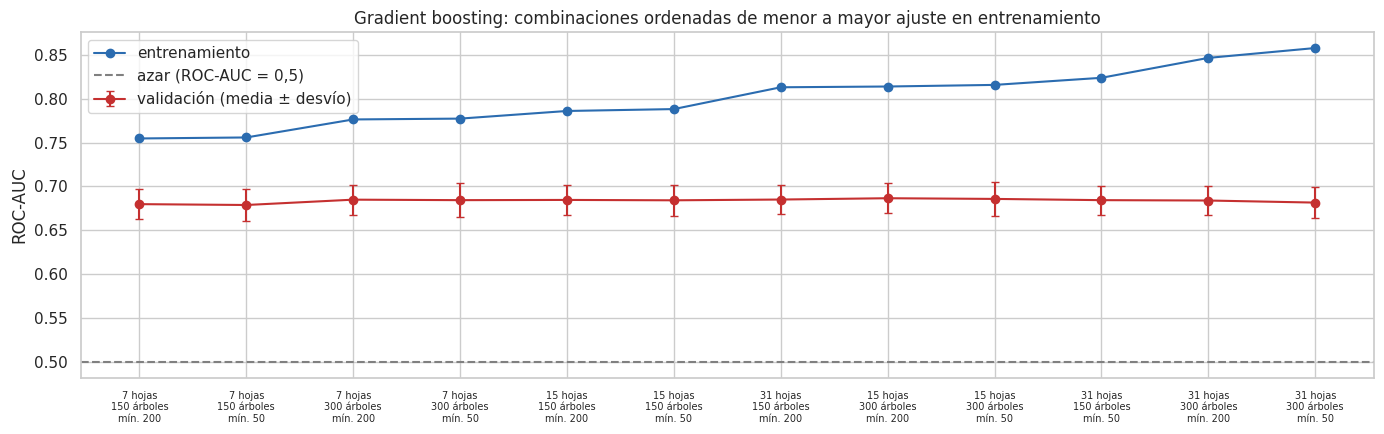

Mejor combinación, bloque por bloque:


,período validado,ROC-AUC del modelo,proporción de positivos
bloque 1,2022-04-01 -> 2023-07-21,0.659,0.089
bloque 2,2023-07-21 -> 2024-02-03,0.693,0.100
bloque 3,2024-02-03 -> 2024-09-09,0.706,0.099
bloque 4,2024-09-09 -> 2025-03-21,0.698,0.081
bloque 5,2025-03-21 -> 2025-09-25,0.677,0.115


In [28]:
r = pd.DataFrame(busqueda.cv_results_)
tabla_hgb = pd.DataFrame({
    "hojas por árbol": r["param_clf__max_leaf_nodes"], "mín. vuelos por hoja": r["param_clf__min_samples_leaf"],
    "árboles": r["param_clf__max_iter"], "ROC-AUC validación": r["mean_test_roc_auc"],
    "desvío": r["std_test_roc_auc"], "ROC-AUC entrenamiento": r["mean_train_roc_auc"]})
display(tabla_hgb.sort_values("ROC-AUC validación", ascending=False).round(3))

orden = tabla_hgb.sort_values("ROC-AUC entrenamiento").reset_index(drop=True)
etiquetas = [f"{h} hojas\n{a} árboles\nmín. {m}" for h, a, m in
             zip(orden["hojas por árbol"], orden["árboles"], orden["mín. vuelos por hoja"])]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(range(len(orden)), orden["ROC-AUC entrenamiento"], marker="o", color="#2b6cb0", label="entrenamiento")
ax.errorbar(range(len(orden)), orden["ROC-AUC validación"], yerr=orden["desvío"], marker="o", color="#c53030",
            capsize=3, label="validación (media ± desvío)")
ax.axhline(0.5, color="gray", ls="--", label="azar (ROC-AUC = 0,5)")
ax.set_xticks(range(len(orden))); ax.set_xticklabels(etiquetas, fontsize=7)
ax.set_ylabel("ROC-AUC"); ax.set_title("Gradient boosting: combinaciones ordenadas de menor a mayor ajuste en entrenamiento")
ax.legend(); plt.tight_layout(); plt.show()

bloques = pd.DataFrame({
    "período validado": [f"{tr['dt_salida'].iloc[va[0]].date()} -> {tr['dt_salida'].iloc[va[-1]].date()}"
                         for tr in [dataset[m_trva].reset_index(drop=True)] for _, va in tscv.split(X_trva)],
    "ROC-AUC del modelo": [busqueda.cv_results_[f"split{k}_test_roc_auc"][busqueda.best_index_] for k in range(5)],
    "proporción de positivos": [y_trva.iloc[va].mean() for _, va in tscv.split(X_trva)]},
    index=[f"bloque {k + 1}" for k in range(5)])
print("Mejor combinación, bloque por bloque:")
display(bloques.round(3))

**Interpretación.**
- Las 12 combinaciones obtienen una ROC-AUC de validación entre **0,678 y 0,687**. Las nueve mejores difieren en 0,004 como máximo, mucho menos que el desvío entre bloques (≈ 0,018): **los hiperparámetros influyen poco**.
- El gráfico muestra el **sobreajuste**: a medida que el modelo se hace más complejo, la ROC-AUC de entrenamiento sube de 0,755 a 0,857, pero la de validación casi no cambia. El modelo aprende cada vez más detalles de los datos de entrenamiento que no se repiten en el período siguiente.
- En el otro extremo, las dos combinaciones más simples (7 hojas y 150 árboles) rinden algo menos en validación (0,678–0,679): con tan pocos árboles hay un leve **subajuste**.
- Que la validación se estabilice en ~0,69 sin importar la complejidad indica que **el límite está en la información que traen las variables**, no en el ajuste del modelo.
- **Bloque por bloque**, el modelo supera siempre el azar (ROC-AUC entre 0,657 y 0,711). El bloque 1 es el más bajo: entrena con la menor cantidad de datos (48.000 vuelos) y valida sobre un período que atraviesa el hueco de 2022.

## 14. Evaluación del modelo
1. **14.1** Con los hiperparámetros elegidos, el modelo se entrena **solo con el tramo de entrenamiento** y se elige el **umbral de decisión** sobre la **validación**.
2. **14.2** El modelo se reentrena con **entrenamiento + validación** y se evalúa **una única vez** sobre el **test**, con el umbral elegido en el paso anterior.
3. **14.3 y 14.4** Se analiza el modelo: estabilidad en el tiempo y variables más influyentes.

### 14.1 Elección del umbral de decisión (validación)
Por defecto un clasificador marca como positivo todo vuelo con probabilidad ≥ 0,5. Con clases desbalanceadas ese valor no tiene por qué ser el mejor. Se elige el umbral que **maximiza el F1** en la validación. Es lo recomendado para datos desbalanceados y equilibra no perder anomalías (recall o sensibilidad) con no generar falsas alarmas (precisión).

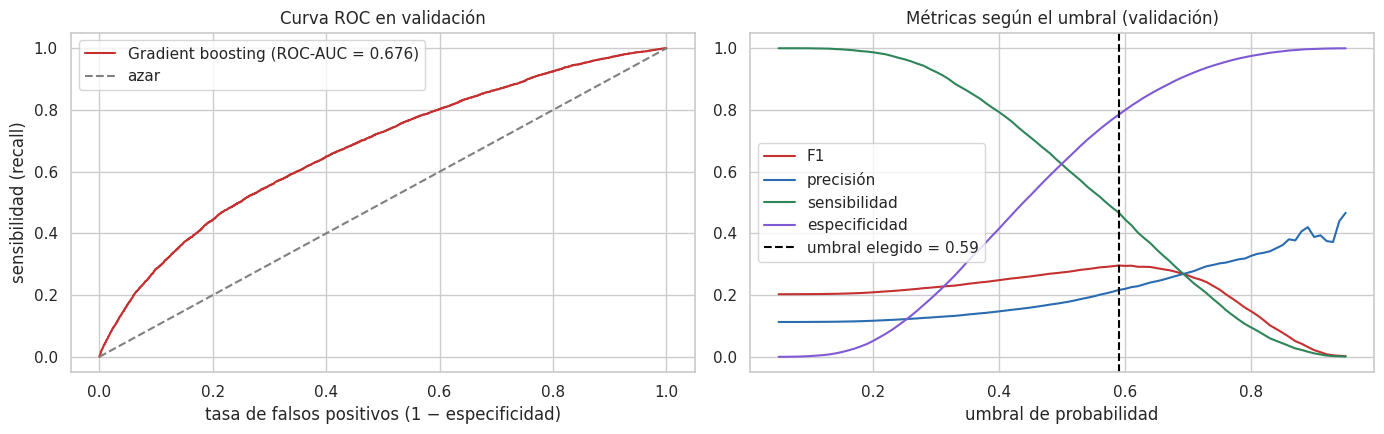

,umbral,F1,precisión,sensibilidad,especificidad,ROC-AUC,proporción de positivos
Gradient boosting,0.59,0.296,0.217,0.467,0.786,0.676,0.113


In [29]:
from sklearn.base import clone
from sklearn.metrics import (precision_recall_curve, roc_curve, roc_auc_score, f1_score, precision_score,
                             recall_score, confusion_matrix, ConfusionMatrixDisplay, classification_report)

MODELO = "Gradient boosting"

def umbral_max_f1(y, p):
    prec, rec, umb = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    k = np.argmax(f1[:-1])
    return umb[k], f1[k], prec[k], rec[k]

def especificidad(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return tn / (tn + fp)

modelo_tr = clone(busqueda.best_estimator_).fit(X_all[m_tr], y_all[m_tr])
y_va = y_all[m_va]
p_va = modelo_tr.predict_proba(X_all[m_va])[:, 1]
umbral, f1_va, prec_va, rec_va = umbral_max_f1(y_va, p_va)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
fpr, tpr, _ = roc_curve(y_va, p_va)
ax[0].plot(fpr, tpr, color="#c53030", label=f"{MODELO} (ROC-AUC = {roc_auc_score(y_va, p_va):.3f})")
ax[0].plot([0, 1], [0, 1], color="gray", ls="--", label="azar")
ax[0].set_xlabel("tasa de falsos positivos (1 − especificidad)"); ax[0].set_ylabel("sensibilidad (recall)")
ax[0].set_title("Curva ROC en validación"); ax[0].legend()
umbs = np.linspace(0.05, 0.95, 91)
curvas = pd.DataFrame([{"umbral": u, "F1": f1_score(y_va, p_va >= u), "precisión": precision_score(y_va, p_va >= u, zero_division=0),
                        "sensibilidad": recall_score(y_va, p_va >= u), "especificidad": especificidad(y_va, p_va >= u)} for u in umbs])
for col, color in zip(["F1", "precisión", "sensibilidad", "especificidad"], ["#c53030", "#2b6cb0", "#2f855a", "#805ad5"]):
    ax[1].plot(curvas["umbral"], curvas[col], color=color, label=col)
ax[1].axvline(umbral, color="black", ls="--", label=f"umbral elegido = {umbral:.2f}")
ax[1].set_xlabel("umbral de probabilidad"); ax[1].set_title("Métricas según el umbral (validación)"); ax[1].legend()
plt.tight_layout(); plt.show()

pred_va = (p_va >= umbral).astype(int)
display(pd.DataFrame({"umbral": [umbral], "F1": [f1_va], "precisión": [prec_va], "sensibilidad": [rec_va],
                      "especificidad": [especificidad(y_va, pred_va)], "ROC-AUC": [roc_auc_score(y_va, p_va)],
                      "proporción de positivos": [y_va.mean()]}, index=[MODELO]).round(3))

**Interpretación.**
- **Curva ROC:** la curva queda por encima de la diagonal del azar en todo su recorrido (ROC-AUC = 0,678 en validación). Para detectar más anomalías (subir la sensibilidad) hay que aceptar cada vez más falsos positivos.
- El F1 máximo en validación (**0,296**) se alcanza con un umbral de **0,62**: sensibilidad de 40,8 %, especificidad de 82,9 % y precisión de 23,3 %.
- El umbral queda por encima de 0,5 porque el modelo se entrenó con clases igualadas (undersampling, 13.1) y estima probabilidades más altas que la proporción real de anómalos.
- El gráfico de la derecha muestra el compromiso: subir el umbral aumenta la especificidad y la precisión, y reduce la sensibilidad. La curva de F1 es bastante **plana** entre ~0,5 y ~0,7, así que la elección exacta del umbral no es crítica.

### 14.2 Evaluación final en el conjunto de test

,Gradient boosting,referencia sin información
ROC-AUC,0.695,0.500
precisión,0.213,0.097
sensibilidad (recall),0.379,1.000
especificidad,0.850,0.000
F1,0.273,0.176
accuracy,0.805,0.903
% vuelos alertados,17.174,100.000


Referencia sin información: ROC-AUC = 0,5 (azar); precisión, sensibilidad, especificidad y F1 = alertar todos los vuelos; accuracy = predecir siempre 'normal'.


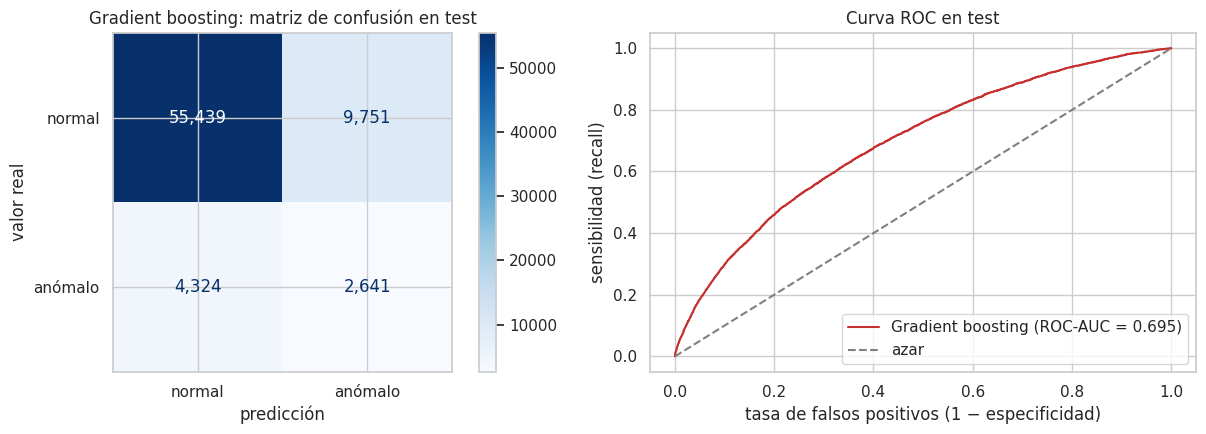

              precision    recall  f1-score   support

      normal      0.928     0.850     0.887     65190
     anómalo      0.213     0.379     0.273      6965

    accuracy                          0.805     72155
   macro avg      0.570     0.615     0.580     72155
weighted avg      0.859     0.805     0.828     72155



In [30]:
modelo_final = clone(busqueda.best_estimator_).fit(X_all[m_trva], y_all[m_trva])
y_te = y_all[m_te]
p_te = modelo_final.predict_proba(X_all[m_te])[:, 1]
pred_te = (p_te >= umbral).astype(int)
prev = y_te.mean()

res_test = pd.DataFrame({
    MODELO: [roc_auc_score(y_te, p_te), precision_score(y_te, pred_te), recall_score(y_te, pred_te),
             especificidad(y_te, pred_te), f1_score(y_te, pred_te), (pred_te == y_te).mean(), pred_te.mean() * 100],
    "referencia sin información": [0.5, prev, 1.0, 0.0, 2 * prev / (1 + prev), 1 - prev, 100.0]},
    index=["ROC-AUC", "precisión", "sensibilidad (recall)", "especificidad", "F1", "accuracy", "% vuelos alertados"])
display(res_test.round(3))
print("Referencia sin información: ROC-AUC = 0,5 (azar); precisión, sensibilidad, especificidad y F1 = alertar todos los vuelos;"
      " accuracy = predecir siempre 'normal'.")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=["normal", "anómalo"]).plot(ax=ax[0], cmap="Blues", values_format=",")
ax[0].set_title(f"{MODELO}: matriz de confusión en test"); ax[0].set_xlabel("predicción"); ax[0].set_ylabel("valor real")
fpr, tpr, _ = roc_curve(y_te, p_te)
ax[1].plot(fpr, tpr, color="#c53030", label=f"{MODELO} (ROC-AUC = {roc_auc_score(y_te, p_te):.3f})")
ax[1].plot([0, 1], [0, 1], color="gray", ls="--", label="azar")
ax[1].set_xlabel("tasa de falsos positivos (1 − especificidad)"); ax[1].set_ylabel("sensibilidad (recall)")
ax[1].set_title("Curva ROC en test"); ax[1].legend()
plt.tight_layout(); plt.show()
print(classification_report(y_te, pred_te, target_names=["normal", "anómalo"], digits=3))

**Interpretación.**
- En el test, con el umbral elegido en validación, el modelo obtiene una **ROC-AUC de 0,695**, contra 0,5 del azar. Es incluso algo mayor que en validación (0,678): el desempeño se sostiene en un período nunca visto.
- **Matriz de confusión:**
  - De los **6.965 vuelos anómalos** detecta **2.275** (sensibilidad de **32,7 %**) y no detecta 4.690.
  - De los 65.190 vuelos normales clasifica bien 57.583 (especificidad de **88,3 %**) y genera 7.607 falsas alarmas.
  - Alerta en total 9.882 vuelos (13,7 %), de los cuales 2.275 son anómalos: una **precisión de 23,0 %**, 2,4 veces la tasa base (9,7 %). Dicho de otro modo, casi 1 de cada 4 alertas es correcta, contra 1 de cada 10 si se alertara al azar.
  - Su F1 (0,270) supera al de alertar todos los vuelos (0,176).
- **Accuracy:** el modelo tiene 83,0 %, **menos** que un predictor que siempre dice "normal" (90,3 %). Confirma lo anticipado en la Sección 11: con clases desbalanceadas la accuracy premia ignorar la clase minoritaria y no sirve para evaluar el modelo.
- Respecto de la validación, el F1 baja poco (de 0,296 a 0,270) y la sensibilidad baja de 40,8 % a 32,7 %, mientras la especificidad sube de 82,9 % a 88,3 %: en el test el modelo alerta menos.

### 14.3 Estabilidad del desempeño en el tiempo y por sentido

,vuelos,tasa real,% alertados,recall,precisión,especificidad
dt_salida,,,,,,
2025-09,1365.0,0.101,0.176,0.297,0.171,0.838
2025-10,7609.0,0.100,0.162,0.372,0.230,0.862
2025-11,7345.0,0.101,0.138,0.299,0.219,0.880
2025-12,7372.0,0.090,0.160,0.341,0.193,0.859
2026-01,7475.0,0.071,0.062,0.165,0.189,0.946
2026-02,6341.0,0.073,0.073,0.145,0.145,0.933
2026-03,7412.0,0.074,0.057,0.204,0.267,0.955
2026-04,7060.0,0.076,0.102,0.197,0.147,0.905
2026-05,6433.0,0.105,0.274,0.578,0.221,0.762


,vuelos,tasa real,% alertados,recall,precisión,especificidad
sentido,,,,,,
llega_AER,35974.0,0.125,0.204,0.389,0.238,0.822
sale_AER,36181.0,0.068,0.139,0.361,0.177,0.877


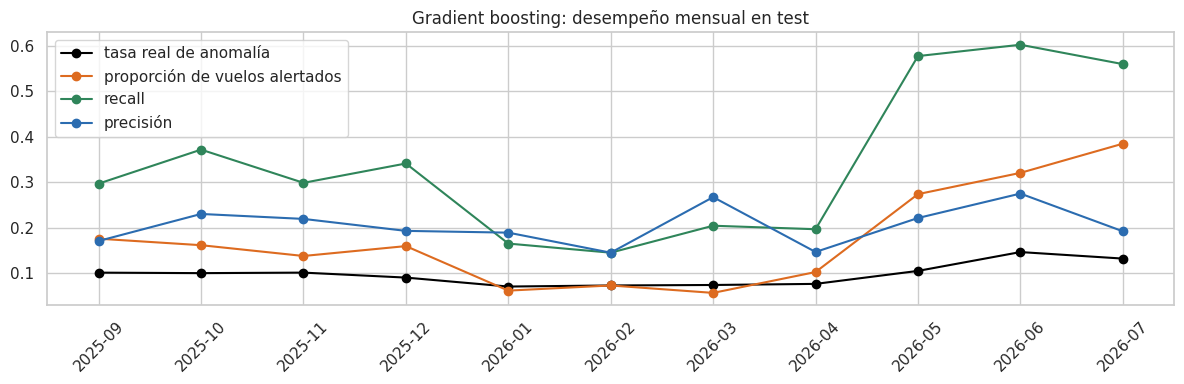

In [31]:
te = dataset.loc[m_te, ["dt_salida", "sentido", TARGET]].assign(pred=pred_te, proba=p_te)
def metricas(g):
    return pd.Series({"vuelos": len(g), "tasa real": g[TARGET].mean(), "% alertados": g["pred"].mean(),
                      "recall": recall_score(g[TARGET], g["pred"], zero_division=0),
                      "precisión": precision_score(g[TARGET], g["pred"], zero_division=0),
                      "especificidad": especificidad(g[TARGET], g["pred"])})
por_mes = te.groupby(te["dt_salida"].dt.to_period("M")).apply(metricas)
por_mes = por_mes[por_mes["vuelos"] >= 1000]          # se excluye el mes con solo unas horas de datos
display(por_mes.round(3))
display(te.groupby("sentido").apply(metricas).round(3))

fig, ax = plt.subplots(figsize=(12, 4))
x = por_mes.index.astype(str)
ax.plot(x, por_mes["tasa real"], marker="o", color="black", label="tasa real de anomalía")
ax.plot(x, por_mes["% alertados"], marker="o", color="#dd6b20", label="proporción de vuelos alertados")
ax.plot(x, por_mes["recall"], marker="o", color="#2f855a", label="recall")
ax.plot(x, por_mes["precisión"], marker="o", color="#2b6cb0", label="precisión")
ax.set_title(f"{MODELO}: desempeño mensual en test"); ax.legend(); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**Interpretación.**
- **El desempeño cambia con la estación.** En enero, febrero y marzo, con una tasa real baja (7,1–7,4 %), el modelo alerta muy pocos vuelos (3,7–4,0 %): la especificidad es altísima (96–97 %), pero la sensibilidad cae a **10–14 %**. De mayo a julio, con más anomalías, alerta más (23–34 %) y la sensibilidad sube a **51–55 %**, mientras la especificidad baja a 69–80 %.
- La **precisión es más estable** (entre 16 % y 30 % todos los meses): cuando el modelo alerta, acierta con una frecuencia parecida a lo largo del año.
- La proporción de alertas acompaña a la tasa real, que sube hacia el invierno (como se vio en el EDA, 6.4), pero en verano el modelo casi no anticipa las anomalías que igual ocurren.
- **Por sentido:** en el test, los vuelos que llegan a AER tienen una tasa real casi el doble que los que salen (12,5 % contra 6,8 %). En entrenamiento esa diferencia no existía (chi-cuadrado no significativo, 6.6). Es un ejemplo del **cambio de las relaciones con el tiempo** que advierte la clase de series temporales, y un argumento para **reentrenar el modelo periódicamente**. Aun sin usar `sentido`, el modelo es más preciso con las llegadas (25,7 % contra 19,3 %), con una sensibilidad similar en ambos sentidos (≈ 33 %).

### 14.4 Importancia de las variables
Se usa **importancia por permutación** sobre el test: se mezcla al azar una variable por vez y se mide cuánto empeora la ROC-AUC. Si empeora mucho, el modelo depende de esa variable. Se calcula sobre una muestra de 20.000 vuelos del test con 5 repeticiones.

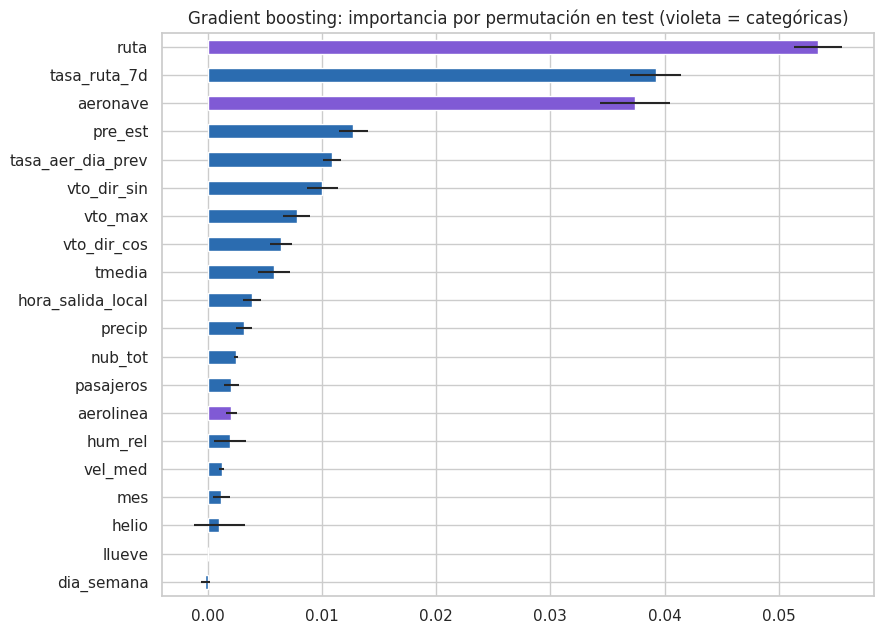

,caída de ROC-AUC,desvío
ruta,0.0534,0.0021
tasa_ruta_7d,0.0392,0.0022
aeronave,0.0374,0.0031
pre_est,0.0128,0.0013
tasa_aer_dia_prev,0.0109,0.0008
vto_dir_sin,0.0100,0.0014
vto_max,0.0078,0.0012
vto_dir_cos,0.0064,0.0010
tmedia,0.0058,0.0014
hora_salida_local,0.0039,0.0008


In [32]:
from sklearn.inspection import permutation_importance
muestra = X_all[m_te].sample(20_000, random_state=SEED)
pi = permutation_importance(modelo_final, muestra, y_all[muestra.index], scoring="roc_auc",
                            n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"caída de ROC-AUC": pi.importances_mean, "desvío": pi.importances_std}, index=muestra.columns)
imp = imp.sort_values("caída de ROC-AUC")
fig, ax = plt.subplots(figsize=(9, 6.5))
imp["caída de ROC-AUC"].plot.barh(xerr=imp["desvío"], ax=ax, color=["#805ad5" if c in FEATURES_CAT else "#2b6cb0" for c in imp.index])
ax.set_title(f"{MODELO}: importancia por permutación en test (violeta = categóricas)")
plt.tight_layout(); plt.show()
display(imp.sort_values("caída de ROC-AUC", ascending=False).round(4))

**Interpretación.**
- Las tres variables más importantes son **`ruta`** (la ROC-AUC cae 0,052 al mezclarla), la **ventana móvil de la ruta `tasa_ruta_7d`** (0,040) y **`aeronave`** (0,037). Les siguen la presión (`pre_est`), la dirección del viento (`vto_dir_sin`), la tasa de AER del día anterior (`tasa_aer_dia_prev`) y la ráfaga máxima (`vto_max`).
- Las **dos variables temporales** están entre las seis más importantes. Esto confirma que aprovechar la estructura de serie temporal (lo que pasó en los días anteriores) aporta información que el resto de las variables no tiene.
- `ruta` tenía una asociación débil **por sí sola**. Que acá sea la más importante indica que el modelo la usa **combinada con otras variables**: por ejemplo, con la ventana móvil de esa misma ruta o con el clima.
- `mes` casi no aporta (0,0002) pese a ser una de las señales más fuertes del EDA. Ocurre porque la temperatura, la presión y las ventanas móviles también reflejan la estación: si se mezcla solo `mes`, el modelo obtiene la estacionalidad de esas otras variables. La importancia por permutación **subestima** las variables correlacionadas entre sí.
- **No aportan:** `llueve` (la información ya está en `precip`) y `dia_semana` (importancia levemente negativa, es decir, ruido). Coincide con la señal débil que mostró `dia_semana` en el EDA. Son candidatas a eliminarse para simplificar el modelo.

## 15. Conclusiones

### Respuesta al objetivo
El objetivo era predecir si un vuelo tendrá una duración anómala, es decir, por encima del P90 de su ruta. **Se puede anticipar en parte**, con información conocida antes del vuelo, pero no con la precisión necesaria para una alarma automática:

- En el test, el modelo obtiene una **ROC-AUC de 0,695** (0,5 sería el azar) y un **F1 de 0,270**, contra 0,176 de alertar todos los vuelos.
- Detecta el **32,7 %** de los vuelos anómalos (sensibilidad) y clasifica bien el **88,3 %** de los normales (especificidad). Casi **1 de cada 4 alertas** es correcta (precisión de 23,0 %), 2,4 veces más que alertando al azar.
- Para los beneficios planteados en la Introducción (anticipar cuellos de botella y planificar conexiones, tripulaciones y recursos en tierra), el modelo sirve como **apoyo**: señala un grupo reducido de vuelos (13,7 %) donde las anomalías son más del doble de frecuentes. No alcanza para decidir vuelo por vuelo.

### Sobre el proceso
- **Desbalance:** undersampling y ponderación de clases rindieron igual; se eligió undersampling por ser la técnica del programa y la más rápida.
- **Series temporales:** las variables de ventana móvil mostraron que las anomalías se agrupan en el tiempo, y quedaron entre las variables más importantes del modelo (14.4).
- **Límite del modelo:** más complejidad no mejora el resultado. La validación se estanca en una ROC-AUC de ~0,69 mientras el entrenamiento sigue subiendo: **el límite está en la información disponible, no en el ajuste del modelo**.
- La accuracy (83,0 %) quedó por debajo de la de predecir siempre "normal" (90,3 %). Esto confirma que no es una métrica válida para este problema desbalanceado.

### Qué aprendió el modelo
- Las variables más influyentes son **la ruta, la tasa de anomalías de la ruta en la última semana y el modelo de aeronave**, seguidas por el clima del día (presión, viento) y la tasa de AER del día anterior.
- El desempeño **depende de la estación**: la sensibilidad va del 10–14 % en el verano al 51–55 % en el invierno.
- La relación entre `sentido` y el target **cambió con el tiempo**: no existía en entrenamiento y es marcada en el test. El modelo deberá **reentrenarse periódicamente**, como advierte la clase de series temporales.

### Limitaciones
- **Clima observado, no pronosticado:** el modelo usa el registro diario del SMN del mismo día, que resume también horas posteriores al despegue. Para usarlo en la práctica habría que alimentarlo con **pronósticos**, y es esperable que el desempeño sea algo menor.
- **Clima diario y de una sola estación:** no distingue a qué hora llovió o hubo viento, y no incluye visibilidad ni el clima del otro aeropuerto de la ruta.
- **Emparejamiento aproximado:** alrededor del 1 % de los vuelos conserva una duración dudosa, lo que agrega ruido al target.
- **Target relativo:** mide duración inusual respecto del histórico de la ruta, no demora respecto del horario programado, que ANAC no publica.
- **Cobertura:** el entrenamiento tiene el hueco de abril a diciembre de 2022.

### Próximos pasos
1. Incorporar **clima horario** (por ejemplo, reportes aeronáuticos METAR) de AER y del otro aeropuerto de la ruta, usar pronósticos en lugar de observaciones y agregar **feriados**.
2. **Validar el emparejamiento** con la matrícula disponible en 2026 y revisar los vuelos de `DESCONOCIDO` y de modelos de aeronave poco frecuentes.
3. **Simplificar el modelo** quitando las variables sin aporte (`llueve`, `dia_semana`) y comprobar que el desempeño se mantiene.
4. Definir un esquema de **reentrenamiento periódico** y, junto con operaciones, el **costo** de una falsa alarma frente al de una anomalía no detectada, para fijar el umbral según ese costo.

## Uso de herramientas de Inteligencia Artificial
Se utilizó **Claude (Anthropic)** como apoyo en la redacción y en la escritura y depuración de código. El grupo revisó y validó cada resultado y es responsable de las decisiones analíticas tomadas.